# Análisis de Rendimiento y Validación Estadística — Proyecto Monty Hall (HPC)
**Asignatura:** Métodos Numéricos II / Computación Científica — FACET, UNT  
**Plataformas en Evaluación:** Mac M1 (ARM heterogénea: P-cores / E-cores) y Clúster de la Facultad (AMD EPYC 7B12, nodo único, cuota de 12 cores)  
**Archivos de Datos:** `datos/resultados_mac_v2.csv` (Mac, 1600 corridas), `datos/resultados_mac_v2_O3.csv` (Mac con `-O3`, M = 3) y `datos/resultados_cluster_v2.csv` (clúster, 800 corridas)

---

### Objetivos:
1. **Procesamiento de Tiempos:** Agrupar las repeticiones por cada combinación $(M, N, P)$ extrayendo la **mediana estadística** para eliminar ruidos del sistema operativo.
2. **Métricas de HPC:** Calcular el *Speedup* ($S_p$) y la *Eficiencia Paralela* ($E_p$) para evaluar el escalado fuerte frente a la Ley de Amdahl.
3. **Caracterización de Hardware:** Identificar el codo de rendimiento al saturar los núcleos de alto rendimiento (P-cores) e incorporar núcleos de eficiencia (E-cores).
4. **Validación Estocástica:** Comprobar la convergencia asintótica del error de Monte Carlo en el orden $O(1/\sqrt{N})$ y la ausencia de sesgo para cada valor de $M$ (test $t$ por $(M, N)$), en la Mac y en el clúster.
5. **Comparación Cruzada:** Contrastar niveles de optimización (`-O2` vs. `-O3`), el ajuste de Amdahl y Karp-Flatt, y la arquitectura heterogénea (Mac) frente a la homogénea (clúster).

## Paso 1: Carga, Validación e Inspección de Datos

En este paso se realiza la importación del conjunto de datos generado por el script de automatización `run_experimento.sh`. Para garantizar la integridad del análisis, se aplica una lectura defensiva definiendo tipos de datos explícitos (`dtype`) desde la carga —incluyendo `int64` para $N$ para evitar desbordamientos numéricos y `uint64` para la `semilla` estocástica del generador `splitmix64`. 

Además, se limpian posibles espacios en las cabeceras, se confirma la presencia de todas las columnas exportadas por el núcleo en C (`monty_hall.c`), se verifica la ausencia de valores nulos y se descartan registros con tiempos no físicos ($T \le 0$).

In [2]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

In [3]:
# ==============================================================================
# PASO 1: Carga, Validación e Inspección de Datos HPC
# ==============================================================================

def cargar_datos_hpc(csv_path):
    print(f"Intentando cargar archivo: {csv_path} ...")
    
    # 1. Verificación de existencia
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Error: El archivo '{csv_path}' no existe. Verifica la ruta.")
        
    # 2. Cargar los datos asegurando conversiones explícitas de tipos numéricos
    # Agregamos 'semilla' como 'uint64' debido a splitmix64 en C
    df = pd.read_csv(csv_path, dtype={
        'n_procesos': 'int32',
        'N': 'int64',
        'M': 'int32',
        'tiempo': 'float64',
        'victorias_cambiando': 'int64',
        'victorias_manteniendo': 'int64',
        'p_empirico': 'float64',
        'p_teorico': 'float64',
        'error_abs': 'float64',
        'semilla': 'uint64' 
    })
    
    # Limpieza de cabeceras (Elimina espacios accidentales)
    df.columns = df.columns.str.strip()
    
    # 3. Validación lógica de integridad
    filas_iniciales = len(df)
    df.dropna(subset=['N', 'n_procesos', 'tiempo'], inplace=True)
    df = df[df['tiempo'] > 0.0]
    
    filas_descartadas = filas_iniciales - len(df)
    if filas_descartadas > 0:
        print(f"Atención: Se descartaron {filas_descartadas} filas por nulos o tiempos <= 0.")

    # 4. Inspección general del DataFrame
    print("\n--- Previsualización de los primeros registros (head) ---")
    display(df.head()) # Usamos display para mejor formato en Jupyter
    
    print("\n--- Tipos de Datos (dtypes) ---")
    print(df.dtypes)
    
    print("\n--- Verificación de Valores Nulos / Faltantes ---")
    print(df.isnull().sum())
    
    # 5. Resumen del volumen de datos cargados
    print("\n--- Resumen del Muestreo Cargado ---")
    print(f"Total de filas/corridas registradas: {len(df)}")
    print(f"Valores de N presentes: {sorted(df['N'].unique())}")
    print(f"Valores de P (procesos) probados: {sorted(df['n_procesos'].unique())}")
    print(f"Puertas evaluadas (M): {sorted(df['M'].unique())}")
    
    # Repeticiones por combinación (M, N, P): se miden, no se infieren
    reps = df.groupby(['M', 'N', 'n_procesos']).size()
    balanceado = 'diseño balanceado' if reps.min() == reps.max() else 'DISEÑO DESBALANCEADO'
    print(f"Combinaciones (M, N, P): {len(reps)}")
    print(f"Repeticiones por combinación (M, N, P): mín = {reps.min()}, máx = {reps.max()} ({balanceado})")
    
    return df

In [4]:
# Ejecución del Paso 1
# Nota: Ajustamos el nombre para que coincida con el script run_experimento.sh V2
ruta_csv = 'datos/resultados_mac_v2.csv' 
df_monty = cargar_datos_hpc(ruta_csv)

Intentando cargar archivo: datos/resultados_mac_v2.csv ...

--- Previsualización de los primeros registros (head) ---


,n_procesos,tiempo,N,M,victorias_cambiando,victorias_manteniendo,p_empirico,p_teorico,error_abs,semilla
0,1,0.000348,100000,3,66968,33032,0.66968,0.666667,0.003013,1922787680616939152
1,2,0.000096,100000,3,66604,33396,0.66604,0.666667,0.000627,1922787680730277152
2,3,0.000065,100000,3,66584,33416,0.66584,0.666667,0.000827,1922787680834035152
3,4,0.000052,100000,3,66790,33210,0.66790,0.666667,0.001233,1922787680931042152
4,5,0.000100,100000,3,66839,33161,0.66839,0.666667,0.001723,1922787681031765152



--- Tipos de Datos (dtypes) ---
n_procesos                 int32
tiempo                   float64
N                          int64
M                          int32
victorias_cambiando        int64
victorias_manteniendo      int64
p_empirico               float64
p_teorico                float64
error_abs                float64
semilla                   uint64
dtype: object

--- Verificación de Valores Nulos / Faltantes ---
n_procesos               0
tiempo                   0
N                        0
M                        0
victorias_cambiando      0
victorias_manteniendo    0
p_empirico               0
p_teorico                0
error_abs                0
semilla                  0
dtype: int64

--- Resumen del Muestreo Cargado ---
Total de filas/corridas registradas: 1600
Valores de N presentes: [100000, 1000000, 10000000, 100000000, 1000000000]
Valores de P (procesos) probados: [1, 2, 3, 4, 5, 6, 7, 8]
Puertas evaluadas (M): [3, 5, 10, 50]
Combinaciones (M, N, P): 160
Repetici

## Paso 2: Agregación Estadística por Medianas y Extracción de T1

En este paso se agrupan las mediciones por la cantidad de puertas ($M$), el tamaño del problema ($N$) y el número de procesos MPI ($P$). Para cada grupo se calcula la mediana estadística del tiempo de ejecución ($T_p$) y del error absoluto. La mediana permite filtrar valores atípicos (*outliers*) y variaciones temporales causadas por procesos en segundo plano o interrupciones del sistema operativo.

Finalmente, se extrae el tiempo base secuencial ($T_1$), definido como la mediana del tiempo obtenido con $P = 1$ para cada combinación de $M$ y $N$, el cual constituye la referencia para los cálculos de aceleración.

In [5]:
# ==============================================================================
# PASO 2: Agregación Estadística por Medianas y Extracción de T1
# ==============================================================================

# 1. Agrupar por M, N y n_procesos calculando la mediana de 'tiempo' (Tp) y 'error_abs'
# Se incluye 'M' para mantener compatibilidad con datasets de Fase 1 (M=3) y Fase 2 (M=5, 10, 50)
df_agg = df_monty.groupby(['M', 'N', 'n_procesos']).agg(
    Tp=('tiempo', 'median'),
    error_abs_mediana=('error_abs', 'median')
).reset_index()

# 2. Extraer el tiempo secuencial base (T1) para cada (M, N) donde n_procesos == 1
df_t1 = df_agg[df_agg['n_procesos'] == 1][['M', 'N', 'Tp']].rename(columns={'Tp': 'T1'})

# 3. Asociar T1 a cada fila del DataFrame agregado
df_agg = pd.merge(df_agg, df_t1, on=['M', 'N'], how='left')

# 4. Resumen en pantalla de los tiempos base T1 por tamaño de problema
print("--- Tiempos Secuenciales Base (T1) por N y M ---")
for _, row in df_t1.iterrows():
    print(f"M = {int(row['M']):>2d} | N = {int(row['N']):>10,d} | T1 = {row['T1']:.8f} segundos")

print("\n--- Previsualización de los datos agregados por medianas ---")
display(df_agg.head(10))

--- Tiempos Secuenciales Base (T1) por N y M ---
M =  3 | N =    100,000 | T1 = 0.00018950 segundos
M =  3 | N =  1,000,000 | T1 = 0.00189500 segundos
M =  3 | N = 10,000,000 | T1 = 0.01853850 segundos
M =  3 | N = 100,000,000 | T1 = 0.17941900 segundos
M =  3 | N = 1,000,000,000 | T1 = 1.78936550 segundos
M =  5 | N =    100,000 | T1 = 0.00020000 segundos
M =  5 | N =  1,000,000 | T1 = 0.00190800 segundos
M =  5 | N = 10,000,000 | T1 = 0.01850800 segundos
M =  5 | N = 100,000,000 | T1 = 0.17896200 segundos
M =  5 | N = 1,000,000,000 | T1 = 1.78925400 segundos
M = 10 | N =    100,000 | T1 = 0.00019050 segundos
M = 10 | N =  1,000,000 | T1 = 0.00189600 segundos
M = 10 | N = 10,000,000 | T1 = 0.01848600 segundos
M = 10 | N = 100,000,000 | T1 = 0.17969250 segundos
M = 10 | N = 1,000,000,000 | T1 = 1.79168250 segundos
M = 50 | N =    100,000 | T1 = 0.00018900 segundos
M = 50 | N =  1,000,000 | T1 = 0.00188950 segundos
M = 50 | N = 10,000,000 | T1 = 0.01856950 segundos
M = 50 | N = 100,000,

,M,N,n_procesos,Tp,error_abs_mediana,T1
0,3,100000,1,0.000189,0.001110,0.000189
1,3,100000,2,0.000096,0.000680,0.000189
2,3,100000,3,0.000065,0.001017,0.000189
3,3,100000,4,0.000051,0.001128,0.000189
4,3,100000,5,0.000099,0.001295,0.000189
5,3,100000,6,0.000094,0.001470,0.000189
6,3,100000,7,0.000100,0.000613,0.000189
7,3,100000,8,0.000111,0.001345,0.000189
8,3,1000000,1,0.001895,0.000136,0.001895
9,3,1000000,2,0.000938,0.000485,0.001895


## Paso 3: Cálculo de Métricas de HPC (Speedup y Eficiencia)

En este paso se derivan las dos métricas fundamentales para evaluar el rendimiento y la escalabilidad del algoritmo paralelo bajo la metodología de Escalado Fuerte (*Strong Scaling*):

1. **Speedup ($S_p$):** Mide la aceleración relativa obtenida al utilizar $P$ procesos respecto al tiempo de ejecución base en un solo proceso ($T_1$):
   $$S_p = \frac{T_1}{T_p}$$

2. **Eficiencia Paralela ($E_p$):** Indica la proporción del poder de cómputo efectivamente aprovechada por el sistema con $P$ procesos (porcentaje de retorno del hardware):
   $$E_p = \frac{S_p}{P} = \frac{T_1}{P \cdot T_p}$$

Estas métricas se incorporan al DataFrame consolidado y se resumen en tablas matriciales ($N \times P$) para su fácil inspección previa a la fase de visualización.

In [6]:
# ==============================================================================
# PASO 3: Cálculo de Métricas de HPC (Speedup y Eficiencia)
# ==============================================================================

# 1. Validación de integridad temporal
if (df_agg['Tp'] <= 0).any():
    raise ValueError("Error: Existen valores de Tp <= 0 en los datos agregados.")

# 2. Derivar el Speedup: Sp = T1 / Tp
df_agg['speedup'] = df_agg['T1'] / df_agg['Tp']

# 3. Derivar la Eficiencia Paralela: Ep = Sp / P
df_agg['eficiencia'] = df_agg['speedup'] / df_agg['n_procesos']

# 4. Previsualización de la tabla consolidada
print("--- Previsualización de Métricas de HPC Consolidadas ---")
cols_mostrar = ['M', 'N', 'n_procesos', 'Tp', 'T1', 'speedup', 'eficiencia', 'error_abs_mediana']
cols_validas = [c for c in cols_mostrar if c in df_agg.columns]
display(df_agg[cols_validas].head(12))

# 5. Vista matricial de Speedup (filas = M, N | columnas = P)
pivot_speedup = df_agg.pivot(index=['M', 'N'], columns='n_procesos', values='speedup')
print("\n--- Matriz de Speedup S_p (filas=(M, N), columnas=P) ---")
display(pivot_speedup.round(3))

# 6. Vista matricial de Eficiencia (filas = M, N | columnas = P)
pivot_efic = df_agg.pivot(index=['M', 'N'], columns='n_procesos', values='eficiencia')
print("\n--- Matriz de Eficiencia E_p (filas=(M, N), columnas=P) ---")
display(pivot_efic.round(3))

--- Previsualización de Métricas de HPC Consolidadas ---


,M,N,n_procesos,Tp,T1,speedup,eficiencia,error_abs_mediana
0,3,100000,1,0.000189,0.000189,1.000000,1.000000,0.001110
1,3,100000,2,0.000096,0.000189,1.973958,0.986979,0.000680
2,3,100000,3,0.000065,0.000189,2.915385,0.971795,0.001017
3,3,100000,4,0.000051,0.000189,3.679612,0.919903,0.001128
4,3,100000,5,0.000099,0.000189,1.914141,0.382828,0.001295
5,3,100000,6,0.000094,0.000189,2.015957,0.335993,0.001470
6,3,100000,7,0.000100,0.000189,1.904523,0.272075,0.000613
7,3,100000,8,0.000111,0.000189,1.714932,0.214367,0.001345
8,3,1000000,1,0.001895,0.001895,1.000000,1.000000,0.000136
9,3,1000000,2,0.000938,0.001895,2.019180,1.009590,0.000485



--- Matriz de Speedup S_p (filas=(M, N), columnas=P) ---


n_procesos       1      2      3      4      5      6      7      8
M  N                                                               
3  100000      1.0  1.974  2.915  3.680  1.914  2.016  1.905  1.715
   1000000     1.0  2.019  3.022  4.011  2.545  3.008  2.391  2.376
   10000000    1.0  1.992  2.965  3.946  2.585  3.089  2.944  2.865
   100000000   1.0  1.956  2.834  3.581  3.258  3.308  3.225  3.334
   1000000000  1.0  1.959  2.848  3.780  3.708  3.675  3.818  3.797
5  100000      1.0  2.083  3.077  3.922  2.000  2.139  2.247  1.681
   1000000     1.0  2.031  3.041  4.034  2.563  3.036  2.445  3.307
   10000000    1.0  1.970  2.951  3.929  2.583  2.980  2.780  2.845
   100000000   1.0  1.959  2.804  3.621  3.357  3.398  3.461  3.278
   1000000000  1.0  1.972  2.856  3.785  3.751  3.806  3.835  3.922
10 100000      1.0  1.984  2.931  3.735  1.896  1.995  1.877  1.614
   1000000     1.0  2.021  3.026  4.000  2.554  2.935  3.344  2.724
   10000000    1.0  1.983  2.957  3.930  2.576  3.036  2.712  2.862
   100000000   1.0  1.964  2.823  3.602  3.213  3.345  3.511  3.483
   1000000000  1.0  1.960  2.855  3.748  3.718  3.739  3.788  3.737
50 100000      1.0  1.959  2.864  3.706  1.919  2.032  1.688  1.385
   1000000     1.0  2.010  3.014  3.995  2.548  3.006  2.426  2.066
   10000000    1.0  1.983  2.974  3.952  2.599  3.074  2.835  2.802
   100000000   1.0  1.958  2.807  3.608  3.286  3.408  3.328  3.456
   1000000000  1.0  1.975  2.861  3.799  3.758  3.808  3.835  3.753


--- Matriz de Eficiencia E_p (filas=(M, N), columnas=P) ---


n_procesos       1      2      3      4      5      6      7      8
M  N                                                               
3  100000      1.0  0.987  0.972  0.920  0.383  0.336  0.272  0.214
   1000000     1.0  1.010  1.007  1.003  0.509  0.501  0.342  0.297
   10000000    1.0  0.996  0.988  0.986  0.517  0.515  0.421  0.358
   100000000   1.0  0.978  0.945  0.895  0.652  0.551  0.461  0.417
   1000000000  1.0  0.979  0.949  0.945  0.742  0.613  0.545  0.475
5  100000      1.0  1.042  1.026  0.980  0.400  0.357  0.321  0.210
   1000000     1.0  1.015  1.014  1.008  0.513  0.506  0.349  0.413
   10000000    1.0  0.985  0.984  0.982  0.517  0.497  0.397  0.356
   100000000   1.0  0.980  0.935  0.905  0.671  0.566  0.494  0.410
   1000000000  1.0  0.986  0.952  0.946  0.750  0.634  0.548  0.490
10 100000      1.0  0.992  0.977  0.934  0.379  0.332  0.268  0.202
   1000000     1.0  1.011  1.009  1.000  0.511  0.489  0.478  0.341
   10000000    1.0  0.991  0.986  0.983  0.515  0.506  0.387  0.358
   100000000   1.0  0.982  0.941  0.901  0.643  0.557  0.502  0.435
   1000000000  1.0  0.980  0.952  0.937  0.744  0.623  0.541  0.467
50 100000      1.0  0.979  0.955  0.926  0.384  0.339  0.241  0.173
   1000000     1.0  1.005  1.005  0.999  0.510  0.501  0.347  0.258
   10000000    1.0  0.991  0.991  0.988  0.520  0.512  0.405  0.350
   100000000   1.0  0.979  0.936  0.902  0.657  0.568  0.475  0.432
   1000000000  1.0  0.988  0.954  0.950  0.752  0.635  0.548  0.469

### Paso 4.1: Gráfico 1 — Curvas de Speedup vs. Procesos (P) para distintos M

En este panel de gráficos se representa la aceleración ($S_p = T_1 / T_p$) en función del número de procesos MPI ($P$) para cada tamaño de problema ($N = 10^5, 10^6, 10^7, 10^8, 10^9$), evaluado a través de los cuatro escenarios de puertas del concurso ($M \in \{3, 5, 10, 50\}$).

Esta disposición multi-panel ($2 \times 2$) permite contrastar las curvas empíricas de la Fase 1 ($M = 3$) y la Fase 2 ($M = 5, 10, 50$) contra la referencia del Speedup Ideal ($S_p = P$), evidenciando si el incremento en la complejidad de selección de puertas altera la eficiencia de paralelización o si el algoritmo conserva su naturaleza embarazosamente paralela en todas las variantes.

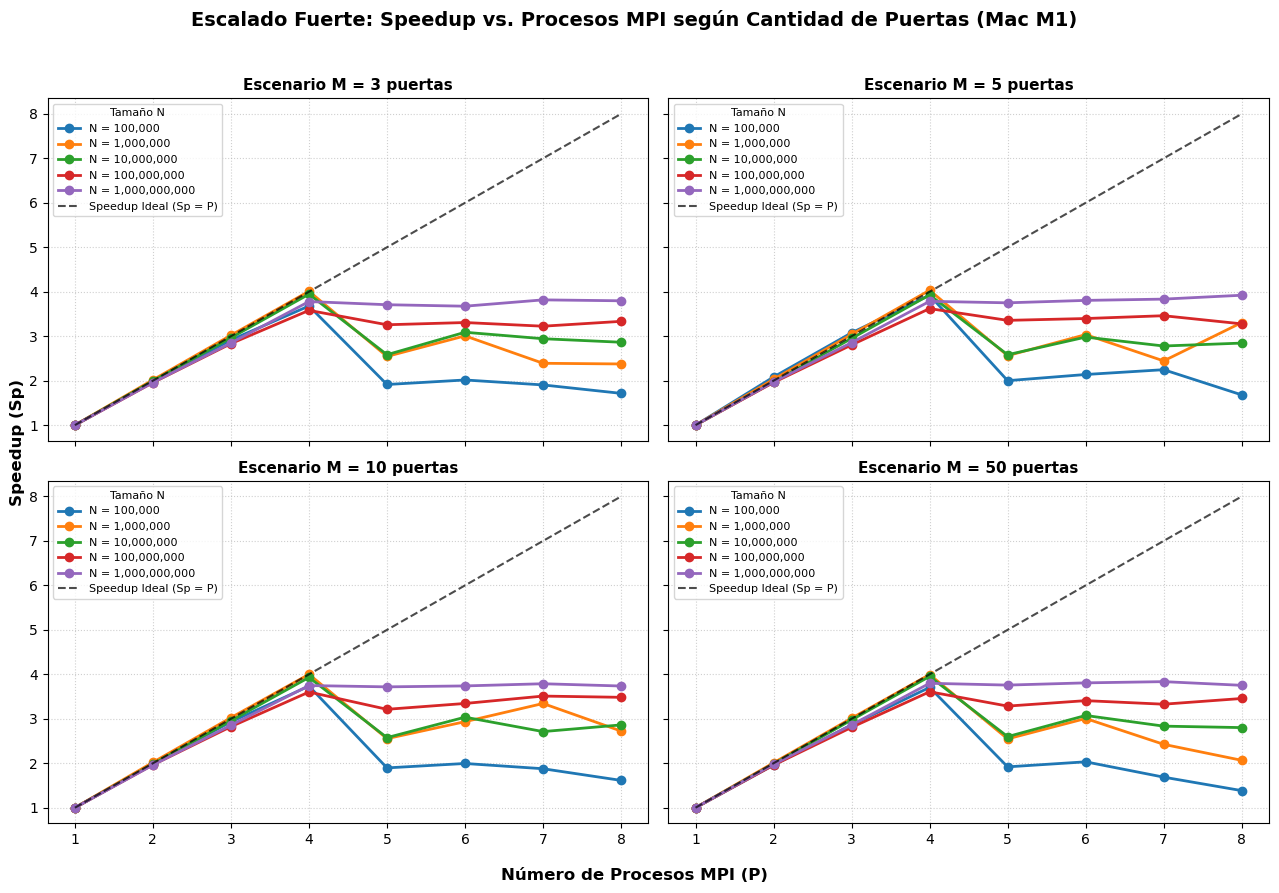

In [7]:
# ==============================================================================
# PASO 4.1: Gráfico 1 - Speedup vs. Procesos (P) Multi-panel (M = 3, 5, 10, 50)
# ==============================================================================

# Extraer listas de valores únicos presentes
valores_M = sorted(df_agg['M'].unique())
valores_P = sorted(df_agg['n_procesos'].unique())
valores_N = sorted(df_agg['N'].unique())

# Crear figura con subgráficos en grilla 2x2
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey=True)
axes_flat = axes.flatten()

for idx, m_val in enumerate(valores_M):
    if idx >= len(axes_flat):
        break
        
    ax = axes_flat[idx]
    df_m = df_agg[df_agg['M'] == m_val]
    
    # Graficar las curvas empíricas para cada N
    for n_val in valores_N:
        subset = df_m[df_m['N'] == n_val].sort_values('n_procesos')
        if not subset.empty:
            ax.plot(subset['n_procesos'], subset['speedup'], marker='o', linewidth=2, label=f'N = {n_val:,}')
            
    # Graficar la referencia de Speedup Ideal (Sp = P)
    ax.plot(valores_P, valores_P, linestyle='--', color='black', alpha=0.7, label='Speedup Ideal (Sp = P)')
    
    # Estilo y anotaciones por subgráfico
    ax.set_title(f'Escenario M = {m_val} puertas', fontsize=11, fontweight='bold')
    ax.set_xticks(valores_P)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(title='Tamaño N', fontsize=8, title_fontsize=8, loc='upper left')

# Etiquetas globales de los ejes
fig.supxlabel('Número de Procesos MPI (P)', fontsize=12, fontweight='bold')
fig.supylabel('Speedup (Sp)', fontsize=12, fontweight='bold')
fig.suptitle('Escalado Fuerte: Speedup vs. Procesos MPI según Cantidad de Puertas (Mac M1)', 
             fontsize=14, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# Guardar la imagen consolidada para el informe
plt.savefig('grafico1_speedup_multiM_mac.png', dpi=300)
plt.show()

### Paso 4.2: Gráfico 2 — Eficiencia Paralela vs. Procesos (P) para distintos M

En este panel de gráficos se representa la Eficiencia Paralela ($E_p = S_p / P$) en función de la cantidad de procesos MPI ($P$) para cada tamaño de problema ($N = 10^5, 10^6, 10^7, 10^8, 10^9$), evaluado a través de los cuatro escenarios de puertas del concurso ($M \in \{3, 5, 10, 50\}$).

En la arquitectura heterogénea del chip Apple M1 (4 P-cores + 4 E-cores), la línea vertical discontinua en $P = 4$ señala la transición a partir de la cual el sistema operativo comienza a asignar procesos a los núcleos de eficiencia (E-cores). Esta disposición multi-panel ($2 \times 2$) permite verificar el desbalance de carga y la degradación del retorno de inversión en hardware al saturar la capacidad de los P-cores bajo distintas complejidades del dominio.

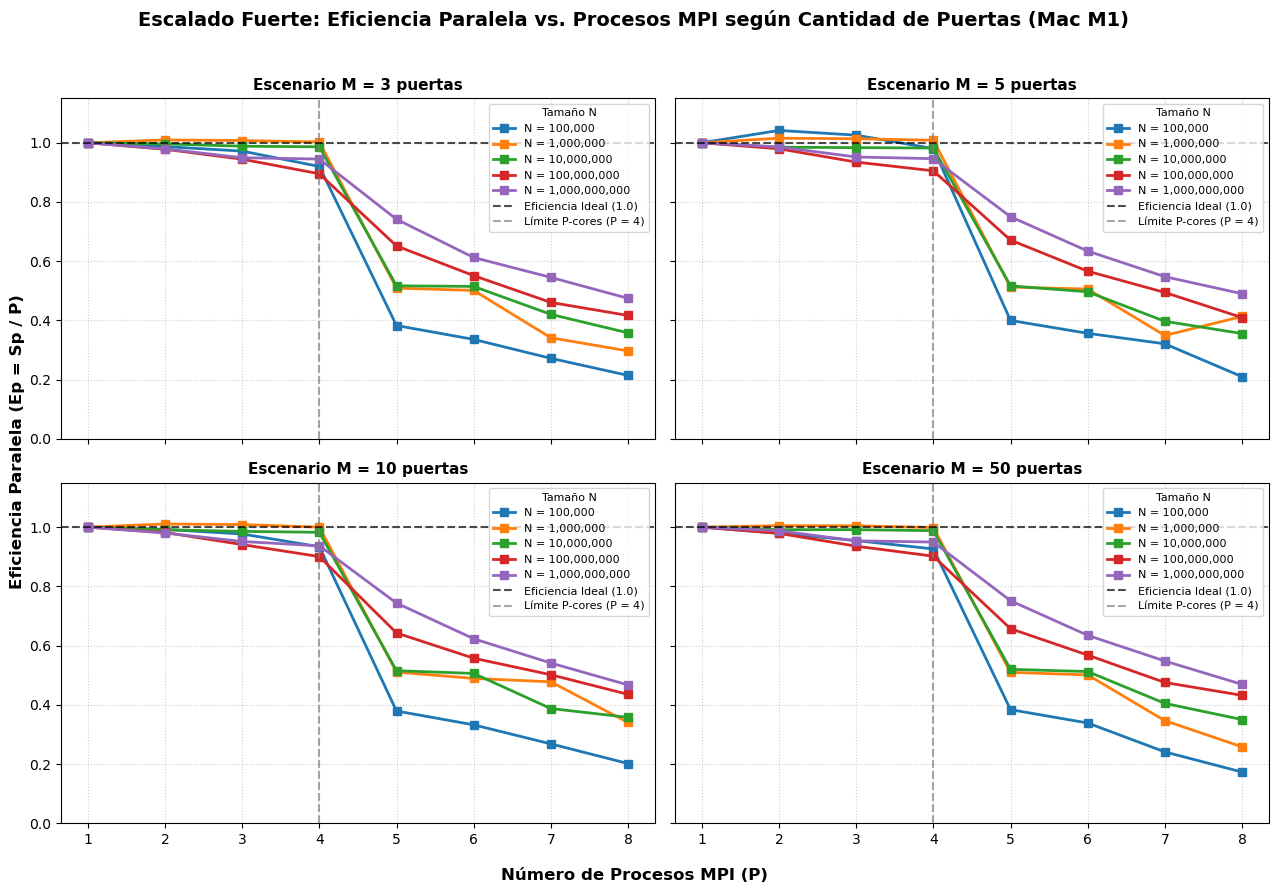

In [8]:
# ==============================================================================
# PASO 4.2: Gráfico 2 - Eficiencia Paralela vs. Procesos (P) Multi-panel (M = 3, 5, 10, 50)
# ==============================================================================

# Extraer listas de valores únicos presentes
valores_M = sorted(df_agg['M'].unique())
valores_P = sorted(df_agg['n_procesos'].unique())
valores_N = sorted(df_agg['N'].unique())

# Crear figura con subgráficos en grilla 2x2
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey=True)
axes_flat = axes.flatten()

for idx, m_val in enumerate(valores_M):
    if idx >= len(axes_flat):
        break
        
    ax = axes_flat[idx]
    df_m = df_agg[df_agg['M'] == m_val]
    
    # Graficar la Eficiencia Paralela empírica para cada N
    for n_val in valores_N:
        subset = df_m[df_m['N'] == n_val].sort_values('n_procesos')
        if not subset.empty:
            ax.plot(subset['n_procesos'], subset['eficiencia'], marker='s', linewidth=2, label=f'N = {n_val:,}')
            
    # Línea de referencia de Eficiencia Ideal (1.0 = 100%)
    ax.axhline(y=1.0, linestyle='--', color='black', alpha=0.7, label='Eficiencia Ideal (1.0)')
    
    # Marcar el límite de P-cores (P = 4 en Apple M1) si P excede los 4 núcleos
    if 4 in valores_P and max(valores_P) > 4:
        ax.axvline(x=4, color='gray', linestyle='--', alpha=0.7, label='Límite P-cores (P = 4)')
    
    # Estilo y anotaciones por subgráfico
    ax.set_title(f'Escenario M = {m_val} puertas', fontsize=11, fontweight='bold')
    ax.set_xticks(valores_P)
    ax.set_ylim(0, 1.15)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(title='Tamaño N', fontsize=8, title_fontsize=8, loc='upper right')

# Etiquetas globales de los ejes
fig.supxlabel('Número de Procesos MPI (P)', fontsize=12, fontweight='bold')
fig.supylabel('Eficiencia Paralela (Ep = Sp / P)', fontsize=12, fontweight='bold')
fig.suptitle('Escalado Fuerte: Eficiencia Paralela vs. Procesos MPI según Cantidad de Puertas (Mac M1)', 
             fontsize=14, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# Guardar la imagen consolidada para el informe
plt.savefig('grafico2_eficiencia_multiM_mac.png', dpi=300)
plt.show()

### Paso 4.3: Gráfico 3 — Convergencia del Error Absoluto vs. N (Escala Log-Log)

En este gráfico se representa la evolución de la mediana del error absoluto respecto al número total de simulaciones ($N$) en escala logarítmica doble ($10^5$ a $10^9$).

Para contrastar de forma rigurosa la **mediana del error absoluto empírico** ($\text{mediana}(|\hat{p} - p_{teo}|)$), la curva teórica de referencia se ajusta a la **mediana esperada** de la distribución normal plegada para $X \sim \mathcal{N}(0, SE^2)$:

$$\text{Mediana Esperada}(|\hat{p} - p_{teo}|) = \Phi^{-1}(0.75) \cdot SE(N) \approx 0.6745 \cdot \sqrt{\frac{p_{teo}(1-p_{teo})}{N}}$$

Donde la probabilidad teórica generalizada para $M$ puertas es $p_{teo} = \frac{M-1}{M}$.

Esta representación en doble escala logarítmica confirma la pendiente de orden asintótico $\mathcal{O}(1/\sqrt{N})$ típica de los métodos de Monte Carlo, eliminando el artefacto de escala entre desvío estándar y mediana.

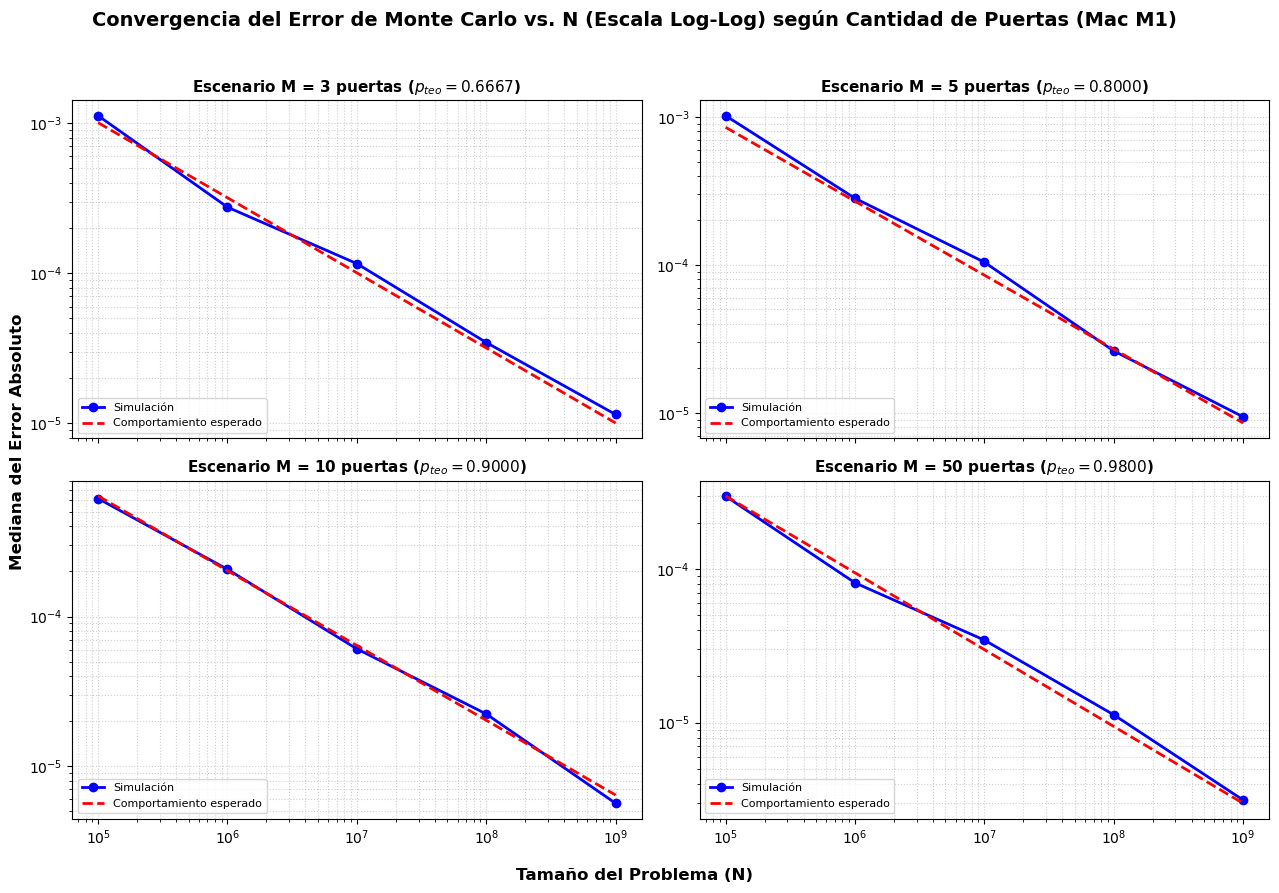

In [9]:
# ==============================================================================
# PASO 4.3: Gráfico 3 - Convergencia del Error Absoluto vs. N (Log-Log)
# ==============================================================================

# Factor de la mediana esperada para X ~ N(0, SE^2): Phi^{-1}(0.75)
factor_mediana = 0.6744897501960817

valores_M = sorted(df_agg['M'].unique())

if len(valores_M) == 1:
    # --------------------------------------------------------------------------
    # Caso individual (ej. Fase 1 con M = 3)
    # --------------------------------------------------------------------------
    m_val = valores_M[0]
    df_m = df_agg[df_agg['M'] == m_val]
    df_error = df_m.groupby('N')['error_abs_mediana'].median().reset_index()
    
    n_array = np.array(df_error['N'], dtype=float)
    error_empirico = np.array(df_error['error_abs_mediana'], dtype=float)
    
    p_teo = (m_val - 1.0) / float(m_val)
    se_teorico = np.sqrt((p_teo * (1.0 - p_teo)) / n_array)
    error_teorico = factor_mediana * se_teorico
    
    plt.figure(figsize=(9, 6))
    plt.loglog(n_array, error_empirico, marker='o', linewidth=2, color='blue', label='Error Absoluto Empírico (Mediana)')
    plt.loglog(n_array, error_teorico, linestyle='--', color='red', linewidth=2, 
               label=r'Mediana Esperada $O(1/\sqrt{N})$ ($0.6745 \cdot SE$)')
    
    plt.xlabel('Tamaño del Problema (N)', fontsize=11)
    plt.ylabel('Mediana del Error Absoluto', fontsize=11)
    plt.title(f'Convergencia del Error de Monte Carlo vs. N (Log-Log, M={m_val})', fontsize=13, fontweight='bold')
    plt.grid(True, which='both', linestyle=':', alpha=0.6)
    plt.legend(fontsize=10)
    plt.tight_layout()
    plt.savefig('grafico3_convergencia_mac.png', dpi=300)
    plt.show()

else:
    # --------------------------------------------------------------------------
    # Caso multi-panel 2x2 para Fase 2 (M = 3, 5, 10, 50)
    # --------------------------------------------------------------------------
    fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
    axes_flat = axes.flatten()

    for idx, m_val in enumerate(valores_M):
        if idx >= len(axes_flat):
            break
            
        ax = axes_flat[idx]
        df_m = df_agg[df_agg['M'] == m_val]
        df_error = df_m.groupby('N')['error_abs_mediana'].median().reset_index()
        
        n_array = np.array(df_error['N'], dtype=float)
        error_empirico = np.array(df_error['error_abs_mediana'], dtype=float)
        
        p_teo = (m_val - 1.0) / float(m_val)
        se_teorico = np.sqrt((p_teo * (1.0 - p_teo)) / n_array)
        error_teorico = factor_mediana * se_teorico
        
        ax.loglog(n_array, error_empirico, marker='o', linewidth=2, color='blue', label='Simulación')
        ax.loglog(n_array, error_teorico, linestyle='--', color='red', linewidth=2, 
                  label=r'Comportamiento esperado')
        
        ax.set_title(f'Escenario M = {m_val} puertas ($p_{{teo}} = {p_teo:.4f}$)', fontsize=11, fontweight='bold')
        ax.grid(True, which='both', linestyle=':', alpha=0.6)
        ax.legend(fontsize=8, loc='lower left')

    fig.supxlabel('Tamaño del Problema (N)', fontsize=12, fontweight='bold')
    fig.supylabel('Mediana del Error Absoluto', fontsize=12, fontweight='bold')
    fig.suptitle('Convergencia del Error de Monte Carlo vs. N (Escala Log-Log) según Cantidad de Puertas (Mac M1)', 
                 fontsize=14, fontweight='bold', y=0.98)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig('grafico3_convergencia_multiM_mac.png', dpi=300)
    plt.show()

## Paso 5: Interpretación y Redacción de Hallazgos (Mac M1)

### 5.1 Caracterización de la Arquitectura Heterogénea: Codo de Rendimiento en P = 4 y Límite Físico

El análisis de las curvas de Speedup ($S_p$) y Eficiencia Paralela ($E_p$) en la plataforma Apple Silicon M1 revela un comportamiento característico determinado por la topología asimétrica del procesador (4 núcleos de alto rendimiento *P-cores* + 4 núcleos de eficiencia *E-cores*):

1. **Región de Escalado Lineal ($P \le 4$):**
Para configuraciones de 1 a 4 procesos MPI, el sistema operativo asigna las tareas prioritariamente a los 4 *P-cores* (Firestorm). Dado que estos núcleos operan a la misma frecuencia máxima (~3.2 GHz) y poseen capacidad de cómputo simétrica, el tiempo de ejecución decrece de forma proporcional a $P$, alcanzando una eficiencia paralela elevada ($E_p \approx 0.90 - 1.01$ para $N \ge 10^6$; con $N = 10^5$ el ruido de medición produce valores de hasta $1.04$).
2. **Punto de Inflexión o "Codo" ($P = 4$):**
Representa el límite físico de núcleos de alto rendimiento disponibles en el chip M1. En este punto se obtiene el máximo aprovechamiento de aceleración antes de introducir asimetría computacional.
3. **Desbalance de Carga y Efecto de Rezagado ($P > 4$):**
Al lanzar 5 o más procesos ($P \in [5, 8]$), el planificador del sistema operativo reparte parte de ellos en los *E-cores* (Icestorm), que operan a una frecuencia de reloj considerablemente menor (~2.0 GHz) y, según el ajuste de $S_8$, rinden aproximadamente la mitad que un *P-core* en este bucle (relación no medida directamente). Dado que el script realiza un reparto estático de la carga ($N/P$ iteraciones por proceso) y la reducción colectiva (`MPI_Reduce`) es una operación bloqueante, el proceso raíz queda detenido esperando la contribución del proceso que corre en el núcleo más lento. Este **efecto de rezagado** (*straggler*, tiempo ocioso $T_{idle}$ en el modelo de la cátedra) provoca que la aceleración se sature en una meseta de $S_p \approx 3.7 - 3.9$ con $N = 10^9$.

#### Sustento Matemático del Techo en $S_8 \approx 4.0$

El tiempo total de la barrera de sincronización en $P = 8$ queda determinado exclusivamente por la velocidad del proceso que corre en el *E-core*:

$$T_8 = \frac{N/8}{\text{Velocidad}_{\text{E-core}}} \approx \frac{N/8}{0.5 \cdot \text{Velocidad}_{\text{P-core}}} = \frac{N}{4 \cdot \text{Velocidad}_{\text{P-core}}} = \frac{T_1}{4}$$

Por lo tanto, bajo reparto estático y con el *E-core* a la mitad de velocidad, el modelo predice $S_8 \approx T_1 / (T_1/4) = 4.0$, en buen acuerdo con el dato empírico ($S_8 \approx 3.8$ con $N = 10^9$).

**Alcance del modelo.** Este razonamiento explica el valor de $S_8$, pero **no la forma de la meseta**: con el mismo supuesto ($S_P = 0.5\,P$ para $P > 4$) predice $S_5 = 2.5$, $S_6 = 3.0$ y $S_7 = 3.5$, mientras que los datos con $N = 10^9$ y $M = 3$ son $3.71$, $3.68$ y $3.82$ (una meseta, no una recta creciente). Una alternativa que describe mejor esa forma es que, para $P > 4$, el sistema entrega $\approx 4$ núcleos *P* de rendimiento sin importar cuántos procesos haya (los *E-cores* aportan poco o nada a este bucle). Ambas explicaciones son compatibles con $S_8$; distinguirlas requiere medir el tiempo de cada rank.

#### Diferencia entre las versiones v1 y v2 (S₈ ≈ 6.3 vs. S₈ ≈ 3.8)

En las pruebas preliminares (v1, con `rand()`) se registraron curvas con $S_8 \approx 6.3$ (con $N = 10^9$: $T_1 = 14.35$ s, $T_4 = 3.80$ s, $T_8 = 2.27$ s). En la versión final (v2, con `splitmix64`) el speedup se estabiliza en $S_8 \approx 3.8$ (con $T_1 = 1.79$ s y $T_4 \approx T_8 \approx 0.47$ s).

Esta diferencia **no es un artefacto del tiempo base $T_1$**:

* En la v1, $S_2 = 1.95$ y $S_4 = 3.78$ quedan *por debajo* del ideal. Un $T_1$ inflado los habría colocado por encima de $P$.
* La reducción de $T_8$ respecto de $T_4$ en la v1 (3.80 s → 2.27 s) fue real en tiempo absoluto: los E-cores sí aportaban.
* `caffeinate` solo evita la suspensión del equipo; **no fija la frecuencia del procesador**.

Lo que cambió entre v1 y v2 es el propio **núcleo de cómputo** (`rand()` frente a `splitmix64`): son dos programas distintos y cada uno mide su propio comportamiento. **Hipótesis (no probada):** el bucle de la v1 estaba limitado por la latencia de la cadena de `rand()`, donde los E-cores rinden proporcionalmente mejor; el bucle de la v2 es corto y con mucho paralelismo a nivel de instrucciones, que favorece a los P-cores. Confirmarlo requeriría tiempos por rank o una prueba controlada.

---

### 5.2 Impacto de la Granularidad del Problema (N Pequeño vs. N Grande)

El volumen total de simulaciones de Monte Carlo ($N$) determina la relación entre tiempo de cómputo útil ($T_{\text{comp}}$) y tiempo de sobrecarga de comunicación/sincronización ($T_{\text{overhead}}$):

* **Granularidad Fina ($N = 10^5$):**
El tiempo de cómputo es del orden de decenas de microsegundos ($T_p \approx 0.05 - 0.11$ ms). Hasta $P = 4$ el escalado es bueno ($S_4 = 3.68$ con $M = 3$), pero con $P \ge 5$ el speedup cae a $\approx 1.4 - 2.2$ según $M$ (con $M = 3$: $1.91$, $2.02$, $1.90$ y $1.71$ para $P = 5$ a $8$) y la eficiencia a $E_p \approx 0.2 - 0.4$. **El speedup se degrada, pero permanece por encima de 1.** Con tan poco trabajo, la latencia de sincronización en `MPI_Reduce` y las variaciones del planificador pesan relativamente más. La inicialización de MPI y la creación de procesos **no** forman parte del tiempo medido (la barrera previa los excluye; ver Plan, §5.2). Con la información disponible este efecto no se puede separar del desbalance entre núcleos: harían falta tiempos por rank.
* **Granularidad Gruesa ($N = 10^8, 10^9$):**
Con $N = 10^9$ el cómputo secuencial dura $1.79$ s ($T_1$ en la Mac) y con $N = 10^8$ unos $0.18$ s. La eficiencia mejora con $N$ para $P > 4$ ($E_8$ con $M = 3$: $0.21$, $0.30$, $0.36$, $0.42$ y $0.47$ para $N = 10^5$ a $10^9$), pero **no se acerca al ideal con $P = 8$**. Hasta $P = 4$ el escalado es casi ideal ($E_p \approx 0.90 - 1.01$) y el ajuste de Amdahl en ese tramo da $f \approx 0.02$ (Paso 5.2); para $P > 4$ la ley no describe los datos (ver Karp-Flatt).

---

### 5.3 Resumen Sintético de Hallazgos para la Defensa Oral

| Aspecto Evaluado | Observación Empírica | Explicación Técnica |
| --- | --- | --- |
| **Punto Óptimo de Trabajo** | $P = 4$ procesos MPI | Coincide exactamente con el total de *P-cores* físicos del chip Apple M1. |
| **Meseta de Aceleración ($P > 4$)** | $S_p \approx 3.7 - 3.9$ con $N = 10^9$ ($S_4 = 3.78$, $S_8 = 3.80$) | El reparto estático $N/P$ acopla el tiempo global al proceso del núcleo más lento; el modelo de *E-core* a la mitad explica $S_8$ pero no la forma de la meseta (ver 5.1). |
| **Cambio de núcleo de cómputo (v1 vs. v2)** | $S_8$ pasa de ≈ 6.3 (`rand()`) a ≈ 3.8 (`splitmix64`) | Son programas distintos; no es un artefacto de $T_1$ (ver 5.1). Hipótesis no probada: latencia de `rand()` frente a paralelismo de instrucciones. |
| **Efecto del Tamaño ($N$)** | Desde $N \approx 10^6$ el escalado hasta $P = 4$ es casi ideal ($E_p \ge 0.9$); para $P > 4$ la eficiencia mejora con $N$ ($E_8$: $0.21 \to 0.47$) sin llegar al ideal | A mayor $N$ se diluye la latencia de sincronización, pero el desbalance entre núcleos persiste. |
| **Cuello de Botella** | Desbalance de carga en $P > 4$ ($T_{idle}$) | Asimetría de velocidad entre *P-cores* y *E-cores* bajo reparto estático (efecto de rezagado). La causa exacta no está aislada: faltan tiempos por rank. |
| **Convergencia Estocástica** | Error mediano consistente con $0.6745 \cdot SE$ hasta $N = 10^9$, para $M = 3, 5, 10, 50$ | Consistente con la tasa asintótica $\mathcal{O}(1/\sqrt{N})$; la ausencia de sesgo se cuantifica en el Paso 6. |

**Recomendación de Ejecución en Mac M1:**

Para producción en esta arquitectura heterogénea conviene usar $P = 4$ procesos MPI: con $N = 10^9$, $P = 8$ no mejora el tiempo ($S_4 = 3.78$ frente a $S_8 = 3.80$) y desperdicia núcleos. El valor de $N$ se elige por la **precisión estadística** requerida ($SE \propto 1/\sqrt{N}$), no por eficiencia: con $P = 4$ la eficiencia es $\approx 1.0$ con $N = 10^6 - 10^7$, baja a $\approx 0.90$ con $N = 10^8$ (anomalía todavía sin explicar) y es $\approx 0.94 - 0.95$ con $N = 10^9$.


## Paso 6: Validación Estocástica y Visualización Teórica vs. Empírica

En este paso se realiza el control de calidad estadístico sobre los datos generados por las corridas de Monte Carlo, evaluando la unicidad de las semillas, la ausencia de sesgo y la convergencia de la probabilidad empírica respecto al valor teórico. Se aplica el mismo procedimiento a la Mac (Paso 6) y al clúster (Paso 6.1b).

### 1. Unicidad de Semillas
Se audita la columna `semilla` para verificar que cada corrida registrada tenga un identificador distinto. La unicidad es una condición **necesaria, no suficiente**, de independencia: la independencia entre los streams de los procesos se apoya además en el período $2^{64}$ de `splitmix64` y en la mezcla de la semilla con el rank (Problema #2 del Plan).

### 2. Criterio Z por Corrida
Se determina el error estándar ($SE_i$) y el puntaje $Z_i$ de cada simulación $i$, con $\hat{p}_i = \text{victorias\_cambiando}_i / N_i$:

$$SE_i = \sqrt{\frac{p_{\text{teo}} \cdot (1 - p_{\text{teo}})}{N_i}} \qquad Z_i = \frac{\hat{p}_i - p_{\text{teo}}}{SE_i}$$

Bajo la aproximación normal, una simulación insesgada debe registrar una tasa cercana al 95 % con $\vert Z_i \vert < 2$. Esta tasa es una prueba de **cobertura**, no de sesgo: un sesgo pequeño y constante se diluye al agregar todos los $N$.

### 3. Test de Sesgo por $(M, N)$
Bajo ausencia de sesgo, $Z_i$ tiene media 0 y varianza 1. Para cada celda $(M, N)$ con $n$ corridas, el promedio $\bar{z}$ tiene desvío $1/\sqrt{n}$, y el estadístico $t = \bar{z}\sqrt{n}$ debe distribuirse aproximadamente como una normal estándar. **Criterio:** $\vert t \vert < 2$ en la gran mayoría de las celdas, ningún $\vert t \vert > 3$ y sin signo sistemático. A modo de referencia, un sesgo constante como el del generador anterior ($-4 \times 10^{-5}$) aparecería con $N = 10^9$ como $\bar{z} \approx -2.7$, es decir, $t \approx -24$ con $n = 80$.

### 4. Comparación Visual por Cantidad de Puertas ($M$)
Se contrasta la probabilidad empírica observada con $N = 10^9$ (la más precisa) contra la teórica $p_{\text{teo}} = (M - 1)/M$, y se grafica el $\bar{z}$ de cada celda $(M, N)$ con su intervalo de confianza del 95 % ($\pm 1.96/\sqrt{n}$): no hay evidencia de sesgo si el intervalo contiene al 0.


==================== Mac M1 ====================
--- Validación de Semillas ---
Total de corridas registradas: 1600 | semillas únicas: 1600
✓ ÉXITO: todas las corridas tienen semillas distintas.

--- Criterio Z por corrida ---
Corridas con |z| < 2: 94.56% (esperado ≈ 95%)

--- Test de sesgo por (M, N): t = z_medio · √n ---
Celdas (M, N): 20 | con |t| > 2: 1 (esperado por azar ≈ 0.9) | con |t| > 3: 0 (esperado ≈ 0.05) | máx |t| = 2.02


n  z_medio  pct_z_negativo  pct_dentro_z2      t
M  N                                                            
3  100000      80    0.187           43.75          93.75  1.676
   1000000     80    0.022           50.00          95.00  0.194
   10000000    80   -0.108           52.50          95.00 -0.967
   100000000   80    0.226           40.00          96.25  2.022
   1000000000  80   -0.012           55.00          96.25 -0.109
5  100000      80   -0.113           53.75          93.75 -1.009
   1000000     80    0.200           36.25          92.50  1.785
   10000000    80   -0.141           62.50          95.00 -1.263
   100000000   80    0.040           51.25          95.00  0.360
   1000000000  80    0.042           47.50          93.75  0.378
10 100000      80    0.131           47.50          96.25  1.170
   1000000     80   -0.156           60.00          92.50 -1.399
   10000000    80   -0.062           56.25          95.00 -0.551
   100000000   80   -0.101           56.25          95.00 -0.903
   1000000000  80   -0.012           43.75          93.75 -0.111
50 100000      80   -0.104           47.50          92.50 -0.932
   1000000     80    0.116           45.00          90.00  1.036
   10000000    80    0.150           45.00          98.75  1.338
   100000000   80    0.037           47.50          96.25  0.334
   1000000000  80    0.046           47.50          95.00  0.414


--- Probabilidad empírica con N = 10^9 (corridas combinadas) vs. teórica ---


,corridas,p_emp,p_teo,diferencia,SE_conjunto,z
M,,,,,,
3,80,0.666666,0.666667,-1.800000e-07,1.670000e-06,-0.108668
5,80,0.800001,0.800000,5.300000e-07,1.410000e-06,0.378231
10,80,0.900000,0.900000,-1.200000e-07,1.060000e-06,-0.110933
50,80,0.980000,0.980000,2.000000e-07,4.900000e-07,0.413708


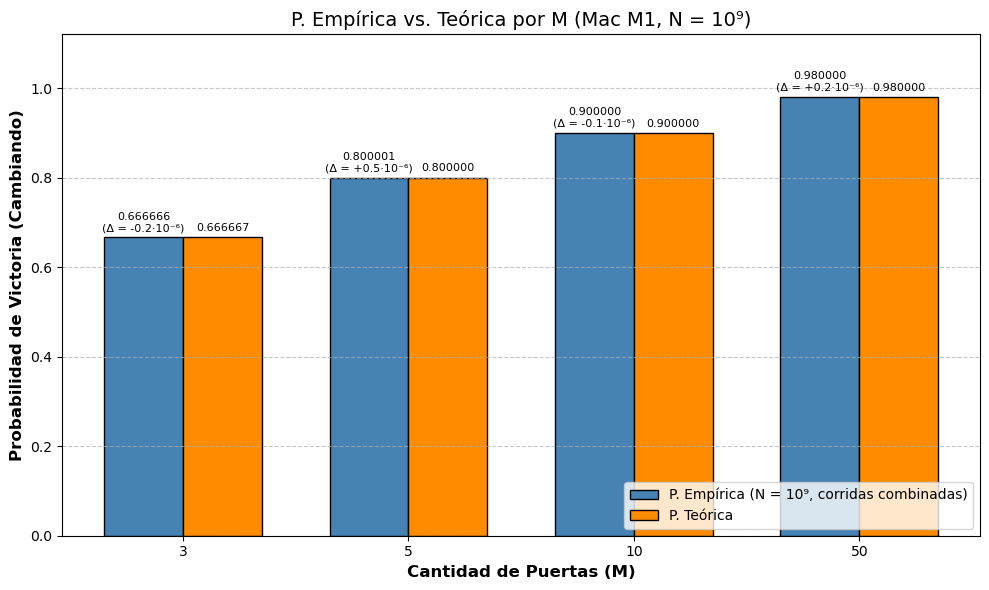

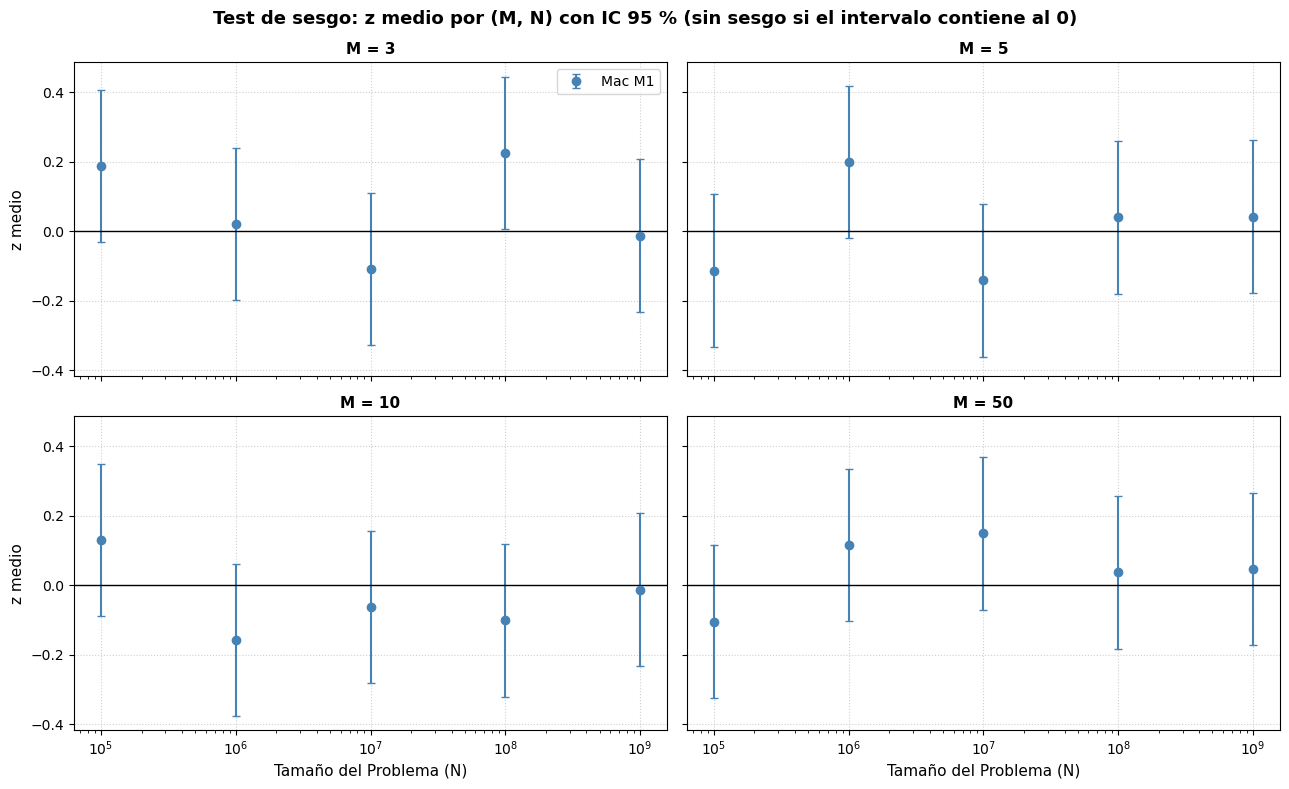

In [10]:
# ==============================================================================
# PASO 6: Validación Estocástica (semillas, criterio Z y test de sesgo por (M, N))
# ==============================================================================

def validacion_estocastica(df, nombre):
    """Semillas únicas, criterio |z| < 2 y test de sesgo (z medio y t) por (M, N).
    Agrega las columnas 'z_score' y 'sesgo_valido' a df y devuelve la tabla por (M, N)."""
    print(f"==================== {nombre} ====================")

    # 1. Semillas únicas
    total, unicas = len(df), df['semilla'].nunique()
    print("--- Validación de Semillas ---")
    print(f"Total de corridas registradas: {total} | semillas únicas: {unicas}")
    if total == unicas:
        print("✓ ÉXITO: todas las corridas tienen semillas distintas.")
    else:
        print(f"⚠ ALERTA: hay colisión de semillas ({total - unicas} repetidas).")

    # 2. Criterio Z por corrida (p̂ exacto a partir de las victorias, sin depender del redondeo del CSV)
    p_hat = df['victorias_cambiando'] / df['N']
    se = np.sqrt(df['p_teorico'] * (1 - df['p_teorico']) / df['N'])
    df['z_score'] = (p_hat - df['p_teorico']) / se
    df['sesgo_valido'] = df['z_score'].abs() < 2
    print("\n--- Criterio Z por corrida ---")
    print(f"Corridas con |z| < 2: {df['sesgo_valido'].mean() * 100:.2f}% (esperado ≈ 95%)")

    # 3. Test de sesgo por (M, N): t = z_medio * sqrt(n)
    g = df.groupby(['M', 'N'])['z_score']
    tabla = pd.DataFrame({
        'n': g.size(),
        'z_medio': g.mean(),
        'pct_z_negativo': g.apply(lambda s: (s < 0).mean() * 100),
        'pct_dentro_z2': g.apply(lambda s: (s.abs() < 2).mean() * 100),
    })
    tabla['t'] = tabla['z_medio'] * np.sqrt(tabla['n'])
    n_cel = len(tabla)
    k2 = int((tabla['t'].abs() > 2).sum())
    k3 = int((tabla['t'].abs() > 3).sum())
    print("\n--- Test de sesgo por (M, N): t = z_medio · √n ---")
    print(f"Celdas (M, N): {n_cel} | con |t| > 2: {k2} (esperado por azar ≈ {n_cel * 0.0455:.1f}) "
          f"| con |t| > 3: {k3} (esperado ≈ {n_cel * 0.0027:.2f}) | máx |t| = {tabla['t'].abs().max():.2f}")
    display(tabla.round(3))
    return tabla


def grafico_sesgo(tablas, archivo):
    """z medio por (M, N) con IC 95 % (±1.96/√n). 'tablas' = {nombre: tabla de validacion_estocastica}."""
    Ms = sorted({m for t in tablas.values() for m, _ in t.index})
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, sharey=True)
    colores = ['steelblue', 'darkorange']
    desplazamientos = [0.85, 1.18] if len(tablas) > 1 else [1.0]
    for ax, M in zip(axes.ravel(), Ms):
        for (nombre, t), col, d in zip(tablas.items(), colores, desplazamientos):
            s = t.xs(M, level='M')
            ax.errorbar(s.index.values * d, s['z_medio'], yerr=1.96 / np.sqrt(s['n']), fmt='o',
                        capsize=3, color=col, label=nombre)
        ax.axhline(0, color='black', linewidth=1)
        ax.set_xscale('log')
        ax.set_title(f'M = {M}', fontsize=11, fontweight='bold')
        ax.grid(True, linestyle=':', alpha=0.6)
    axes[0, 0].legend()
    for ax in axes[1, :]:
        ax.set_xlabel('Tamaño del Problema (N)', fontsize=11)
    for ax in axes[:, 0]:
        ax.set_ylabel('z medio', fontsize=11)
    fig.suptitle('Test de sesgo: z medio por (M, N) con IC 95 % (sin sesgo si el intervalo contiene al 0)',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(archivo, dpi=300)
    plt.show()


tabla_mac = validacion_estocastica(df_monty, 'Mac M1')

# 4. Probabilidad empírica con N = 10^9 (todas las corridas, ponderada) vs. teórica, por M
d9 = df_monty[df_monty['N'] == 10**9]
g9 = d9.groupby('M').agg(victorias=('victorias_cambiando', 'sum'), ensayos=('N', 'sum'),
                         p_teo=('p_teorico', 'first'), corridas=('N', 'size'))
g9['p_emp'] = g9['victorias'] / g9['ensayos']
g9['diferencia'] = g9['p_emp'] - g9['p_teo']
g9['SE_conjunto'] = np.sqrt(g9['p_teo'] * (1 - g9['p_teo']) / g9['ensayos'])
g9['z'] = g9['diferencia'] / g9['SE_conjunto']
print("\n--- Probabilidad empírica con N = 10^9 (corridas combinadas) vs. teórica ---")
display(g9[['corridas', 'p_emp', 'p_teo', 'diferencia', 'SE_conjunto', 'z']].round(8))

fig, ax = plt.subplots(figsize=(10, 6))
bar_width = 0.35
index = np.arange(len(g9))
bar1 = ax.bar(index, g9['p_emp'], bar_width, label='P. Empírica (N = 10⁹, corridas combinadas)', color='steelblue', edgecolor='black')
bar2 = ax.bar(index + bar_width, g9['p_teo'], bar_width, label='P. Teórica', color='darkorange', edgecolor='black')
ax.set_xlabel('Cantidad de Puertas (M)', fontsize=12, fontweight='bold')
ax.set_ylabel('Probabilidad de Victoria (Cambiando)', fontsize=12, fontweight='bold')
ax.set_title('P. Empírica vs. Teórica por M (Mac M1, N = 10⁹)', fontsize=14)
ax.set_xticks(index + bar_width / 2)
ax.set_xticklabels(g9.index)
ax.set_ylim(0, 1.12)
ax.legend(loc='lower right')
ax.grid(axis='y', linestyle='--', alpha=0.7)
for rect, dif in zip(bar1, g9['diferencia']):
    ax.annotate(f'{rect.get_height():.6f}\n(Δ = {dif * 1e6:+.1f}·10⁻⁶)',
                xy=(rect.get_x() + rect.get_width() / 2, rect.get_height()),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8)
for rect in bar2:
    ax.annotate(f'{rect.get_height():.6f}',
                xy=(rect.get_x() + rect.get_width() / 2, rect.get_height()),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.savefig('grafico_p_empirica_vs_teorica.png', dpi=300)
plt.show()

grafico_sesgo({'Mac M1': tabla_mac}, 'grafico_sesgo_z_mac.png')


### Interpretación del test de sesgo (Mac M1)

**Conclusión: no hay evidencia de sesgo en ninguno de los cuatro valores de $M$, y el sesgo del generador anterior quedó eliminado.**

* **Semillas y criterio Z:** las 1600 semillas son distintas. La tasa global con $\vert z \vert < 2$ es 94.56 %, frente al 95 % esperado: la diferencia (−0.44 puntos) equivale a −0.8 desvíos para $n = 1600$.
* **Test de sesgo por $(M, N)$:** de las 20 celdas, solo una tiene $\vert t \vert > 2$ ($M = 3$, $N = 10^8$, $t = 2.02$), y ninguna supera 3; por azar se esperaban $\approx 0.9$ y $\approx 0.05$. Ese único caso es compatible con el azar: su valor $p \approx 0.043$ y, con 20 celdas, la probabilidad de observar al menos una así es $\approx 59\,\%$. Además tiene signo **positivo** (el sesgo anterior era negativo) y no se repite en $N = 10^9$ ($t = -0.11$).
* **Sin signo sistemático:** 11 de las 20 medias $\bar{z}$ son positivas y 9 negativas.
* **Con $N = 10^9$ (la celda más sensible):** $t = -0.11,\ 0.38,\ -0.11,\ 0.41$ para $M = 3, 5, 10, 50$. Con las 80 corridas combinadas, $\hat{p} - p_{\text{teo}}$ es de $-1.8 \times 10^{-7}$, $+5.3 \times 10^{-7}$, $-1.2 \times 10^{-7}$ y $+2.0 \times 10^{-7}$ ($\vert z \vert \le 0.41$). Para $M = 3$, el intervalo de confianza del 95 % de la diferencia es $[-3.5, +3.1] \times 10^{-6}$: el sesgo anterior ($-4 \times 10^{-5}$, con $t \approx -24$ en estas corridas) queda descartado por un factor $\approx 11$.
* **Resultado:** con el generador `splitmix64`, la probabilidad empírica coincide con $(M-1)/M$ dentro del error estadístico, para $M = 3, 5, 10$ y $50$, hasta $N = 10^9$.


## Paso 5.1: Comparación de Niveles de Optimización del Compilador (-O2 vs. -O3)

En este análisis se evalúa el impacto del nivel de optimización aplicado durante la compilación en `mpicc` sobre el tiempo de ejecución y la aceleración (*Speedup*) del simulador de Monte Carlo (`monty_hall.c`).

### 1. Marco Experimental

* **Nivel `-O2` (Optimización Estándar):** Aplica transformaciones de código que incrementan la velocidad de ejecución sin comprometer el tamaño del ejecutable ni la estabilidad del sistema. Incluye propagación de constantes, inlining moderado, reordenamiento de instrucciones y optimización del uso de registros.
* **Nivel `-O3` (Optimización Agresiva):** Activa vectorización automática mediante instrucciones SIMD (*Single Instruction, Multiple Data*), *unrolling* agresivo de bucles y reordenamiento profundo de operaciones matemáticas.

Se espera, como **hipótesis a contrastar con los datos**, que la dependencia de datos secuencial del generador y las bifurcaciones simples limiten las oportunidades de vectorización de `-O3`. La comparación se hace con las corridas **reales** de ambos niveles (`resultados_mac_v2.csv` para `-O2` y `resultados_mac_v2_O3.csv` para `-O3`, ambos con M = 3 y N = 10⁹).


Repeticiones por P: -O2 = [10], -O3 = [10]

--- Comparación -O2 vs. -O3 (N = 1,000,000,000, M = 3) ---


,n_procesos,Tp_O2,Tp_O3,Tp_O3 / Tp_O2,speedup_O2,speedup_O3
0,1,1.7894,1.8001,1.0060,1.0000,1.0000
1,2,0.9136,0.9145,1.0009,1.9586,1.9685
2,3,0.6282,0.6321,1.0061,2.8483,2.8481
3,4,0.4734,0.4801,1.0141,3.7796,3.7494
4,5,0.4825,0.4894,1.0142,3.7084,3.6786
5,6,0.4869,0.4809,0.9877,3.6752,3.7432
6,7,0.4687,0.4684,0.9993,3.8175,3.8431
7,8,0.4713,0.4632,0.9828,3.7968,3.8863


Diferencia máxima de Tp entre -O3 y -O2: 1.72 %


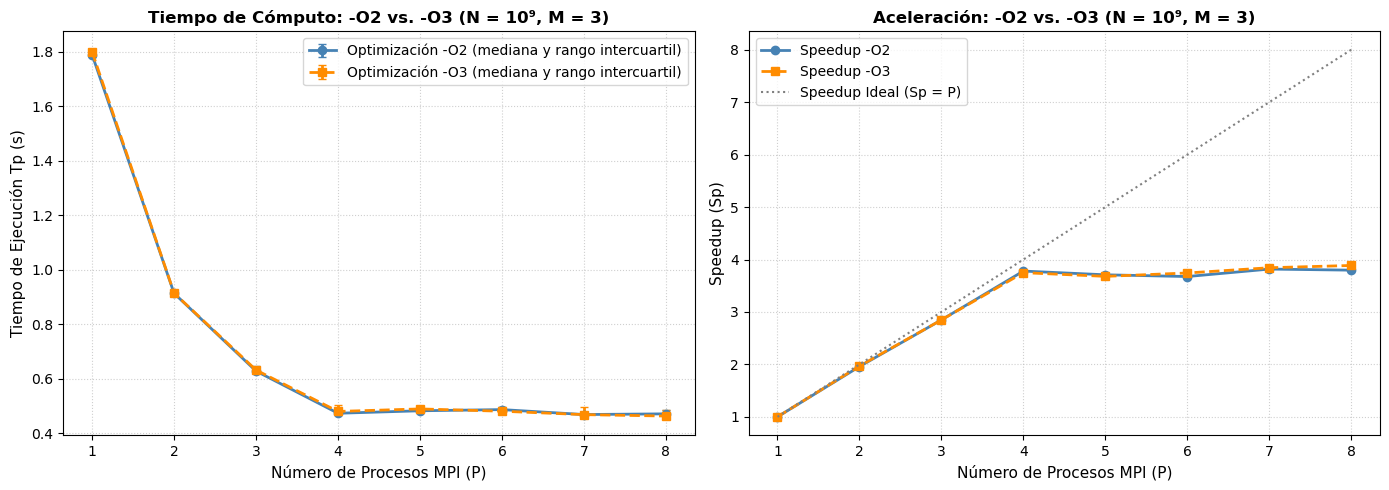

In [11]:
# ==============================================================================
# PASO 5.1: Comparación de Niveles de Optimización (-O2 vs. -O3) con DATOS REALES
# ==============================================================================
# -O2: df_monty (resultados_mac_v2.csv, ya cargado en el Paso 1)
# -O3: resultados_mac_v2_O3.csv (corrida independiente, M = 3)

ruta_o3 = 'datos/resultados_mac_v2_O3.csv'
if not os.path.exists(ruta_o3):
    raise FileNotFoundError(f"No se encontró '{ruta_o3}'. Verifica la ruta (debe estar junto a los otros CSV).")

df_o3 = pd.read_csv(ruta_o3, dtype={
    'n_procesos': 'int32', 'N': 'int64', 'M': 'int32', 'tiempo': 'float64',
    'victorias_cambiando': 'int64', 'victorias_manteniendo': 'int64',
    'p_empirico': 'float64', 'p_teorico': 'float64', 'error_abs': 'float64',
    'semilla': 'uint64'})
df_o3.columns = df_o3.columns.str.strip()

N_CMP, M_CMP = 1_000_000_000, 3

def resumen_opt(df):
    """Mediana y cuartiles de Tp por P (para N y M fijos) y speedup respecto de su propio T1."""
    d = df[(df['N'] == N_CMP) & (df['M'] == M_CMP)]
    g = d.groupby('n_procesos')['tiempo'].agg(
        Tp='median', q1=lambda x: x.quantile(0.25), q3=lambda x: x.quantile(0.75), reps='count'
    ).reset_index()
    g['speedup'] = g.loc[g['n_procesos'] == 1, 'Tp'].iloc[0] / g['Tp']
    return g

r_o2 = resumen_opt(df_monty)
r_o3 = resumen_opt(df_o3)

print(f"Repeticiones por P: -O2 = {sorted(int(x) for x in r_o2['reps'].unique())}, -O3 = {sorted(int(x) for x in r_o3['reps'].unique())}")

comp = r_o2.merge(r_o3, on='n_procesos', suffixes=('_O2', '_O3'))
comp['Tp_O3 / Tp_O2'] = comp['Tp_O3'] / comp['Tp_O2']
print(f"\n--- Comparación -O2 vs. -O3 (N = {N_CMP:,}, M = {M_CMP}) ---")
display(comp[['n_procesos', 'Tp_O2', 'Tp_O3', 'Tp_O3 / Tp_O2', 'speedup_O2', 'speedup_O3']].round(4))
dif_max = (comp['Tp_O3 / Tp_O2'] - 1).abs().max() * 100
print(f"Diferencia máxima de Tp entre -O3 y -O2: {dif_max:.2f} %")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for r, nombre, color, marcador, estilo in [(r_o2, '-O2', 'steelblue', 'o', '-'), (r_o3, '-O3', 'darkorange', 's', '--')]:
    ax1.errorbar(r['n_procesos'], r['Tp'], yerr=[r['Tp'] - r['q1'], r['q3'] - r['Tp']],
                 marker=marcador, linewidth=2, linestyle=estilo, color=color, capsize=3,
                 label=f'Optimización {nombre} (mediana y rango intercuartil)')
    ax2.plot(r['n_procesos'], r['speedup'], marker=marcador, linewidth=2, linestyle=estilo, color=color,
             label=f'Speedup {nombre}')

ax1.set_xlabel('Número de Procesos MPI (P)', fontsize=11)
ax1.set_ylabel('Tiempo de Ejecución Tp (s)', fontsize=11)
ax1.set_title('Tiempo de Cómputo: -O2 vs. -O3 (N = 10⁹, M = 3)', fontsize=12, fontweight='bold')
ax1.set_xticks(r_o2['n_procesos'])
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

ax2.plot(r_o2['n_procesos'], r_o2['n_procesos'], linestyle=':', color='gray', label='Speedup Ideal (Sp = P)')
ax2.set_xlabel('Número de Procesos MPI (P)', fontsize=11)
ax2.set_ylabel('Speedup (Sp)', fontsize=11)
ax2.set_title('Aceleración: -O2 vs. -O3 (N = 10⁹, M = 3)', fontsize=12, fontweight='bold')
ax2.set_xticks(r_o2['n_procesos'])
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.savefig('grafico_opt_o2_vs_o3.png', dpi=300)
plt.show()


### Interpretación de la comparación `-O2` vs. `-O3`

**Conclusión: `-O3` no produce una mejora medible respecto de `-O2` en este bucle.**

- **Tiempos:** el cociente T_p(-O3)/T_p(-O2) queda entre 0,983 y 1,014 (diferencia máxima 1,72 %) y **no tiene signo consistente**: es ≥ 1 para P = 1 a 5 y ≤ 1 para P = 6 a 8. Con P = 1, `-O3` es incluso 0,6 % más lento (1,800 s contra 1,789 s). El promedio de los ocho cocientes es 1,001. Las diferencias son del mismo orden que el rango intercuartil de las repeticiones (las barras del gráfico), así que no se distinguen del ruido con 10 repeticiones por punto.
- **Forma del escalado:** las dos curvas se superponen. Crecen casi linealmente hasta P = 4 (S₄ = 3,78 con `-O2` y 3,75 con `-O3`) y quedan en una meseta de ≈ 3,7 a 3,9 para P > 4. La meseta **no depende del nivel de optimización**; es una propiedad del hardware y del reparto de carga. La corrida con `-O3` sirve además como réplica independiente.
- **Explicación probable (hipótesis, sin inspeccionar el ensamblador):** el bucle ya está muy optimizado con `-O2`, y lo que agrega `-O3` rinde poco. El `% puertas` con divisor variable y la bifurcación `eleccion != premio` difícilmente se vectoricen en NEON. Se puede comprobar comparando el ensamblador (`-S`).
- **Decisión:** se mantiene `-O2` en todas las corridas. **Alcance:** solo Mac, M = 3 y N = 10⁹; el clúster no se probó con `-O3`.

## Paso 5.2: Comparación v1 vs. v2 y Modelos de Escalabilidad (Amdahl y Karp-Flatt)

### 1. Comparativa de Evolución de Código: Versión v1 (Ingenua) vs. v2 (Robusta)

La transición del prototipo ingenuo (`v1`) a la versión definitiva del simulador (`v2`) corrige fallas críticas de estabilidad y precisión estadística:

| Dimensión de Análisis | Versión Ingenua (`v1`) | Versión Final (`v2`) | Justificación Técnica |
| --- | --- | --- | --- |
| **Generador Pseudoaleatorio** | `rand()` / `srand()` de la libc (en macOS, Park-Miller de 32 bits) | `splitmix64` (64 bits, período $2^{64}$) | `rand() % 3` tiene un **sesgo sistemático** de $-2/(3 \cdot 16807) \approx -3.97 \times 10^{-5}$ en $P(\text{cambiar})$ (Problema #5): con $N = 10^9$ el error se estancaba en ≈ $4 \times 10^{-5}$. **No** se debe a un período agotado. |
| **Semillas** | `time(NULL)` (resolución de 1 s) más hash multiplicativo de 32 bits por rank; sin registrar | Semilla de 64 bits desde `clock_gettime` (ns), difundida con `MPI_Bcast`, mezclada por rank con `splitmix64` y registrada en el CSV | Con `time(NULL)` las repeticiones cortas repetían la semilla (15 a 19 resultados distintos sobre 80 filas con $N \le 10^7$; Problema #6). En la v2: 1600 semillas únicas en 1600 corridas. |
| **Contadores** | `int64_t` | `int64_t` | Sin cambios: ya estaba en la v1 (Problema #1). La necesidad de LLP64/Windows quedó fuera del alcance (Mac y clúster son LP64). |
| **Formato de Salida** | Precisión estándar (`%f`) | Precisión extendida (`%.10f`) | Permite auditorías de convergencia en órdenes de magnitud reducidos ($10^{-5}$). |

---

### 2. Modelos Teóricos de Escalabilidad

#### A. Ley de Amdahl (Límite Teórico de Escalado Fuerte)

Dada una fracción estrictamente secuencial $f$ ($0 \le f \le 1$), el *Speedup* máximo alcanzable mediante paralelización con $P$ procesos está acotado por:

$$S_p = \frac{1}{f + \frac{1 - f}{P}}$$

Cuando $P \to \infty$, el límite asintótico del *Speedup* queda restringido exclusivamente por la parte secuencial: $\lim_{P \to \infty} S_p = \frac{1}{f}$.

#### B. Métrica de Karp-Flatt (Fracción Secuencial Experimental)

Para distinguir entre la fracción secuencial propia del algoritmo y los costos añadidos de comunicación o sincronización en MPI, se calcula la fracción secuencial experimental $e$:

$$e = \frac{\frac{1}{S_p} - \frac{1}{P}}{1 - \frac{1}{P}}$$

#### C. Criterio Diagnóstico de Karp-Flatt

* **$e(P)$ permanece constante al aumentar $P$:** La limitación de aceleración responde estrictamente a la fracción de código secuencial (Estructura Algorítmica).
* **$e(P)$ se incrementa monótonamente con $P$:** La degradación del rendimiento obedece a la **sobrecarga de comunicación** (`MPI_Reduce`), latencia de red, desbalance de carga o congestión del bus de memoria.


--- Karp-Flatt e(P), M = 3 (filas = N, columnas = P) ---


n_procesos,2,3,4,5,6,7,8
N,,,,,,,
100000,0.013,0.015,0.029,0.403,0.395,0.446,0.524
1000000,-0.009,-0.004,-0.001,0.241,0.199,0.321,0.338
10000000,0.004,0.006,0.005,0.234,0.188,0.230,0.256
100000000,0.022,0.029,0.039,0.134,0.163,0.195,0.200
1000000000,0.021,0.027,0.019,0.087,0.127,0.139,0.158



Fracción secuencial ajustada con P = 2..4 (N = 10^9): f ≈ 0.021
Amdahl con ese f predice S_8 = 6.97; el dato empírico es S_8 = 3.80


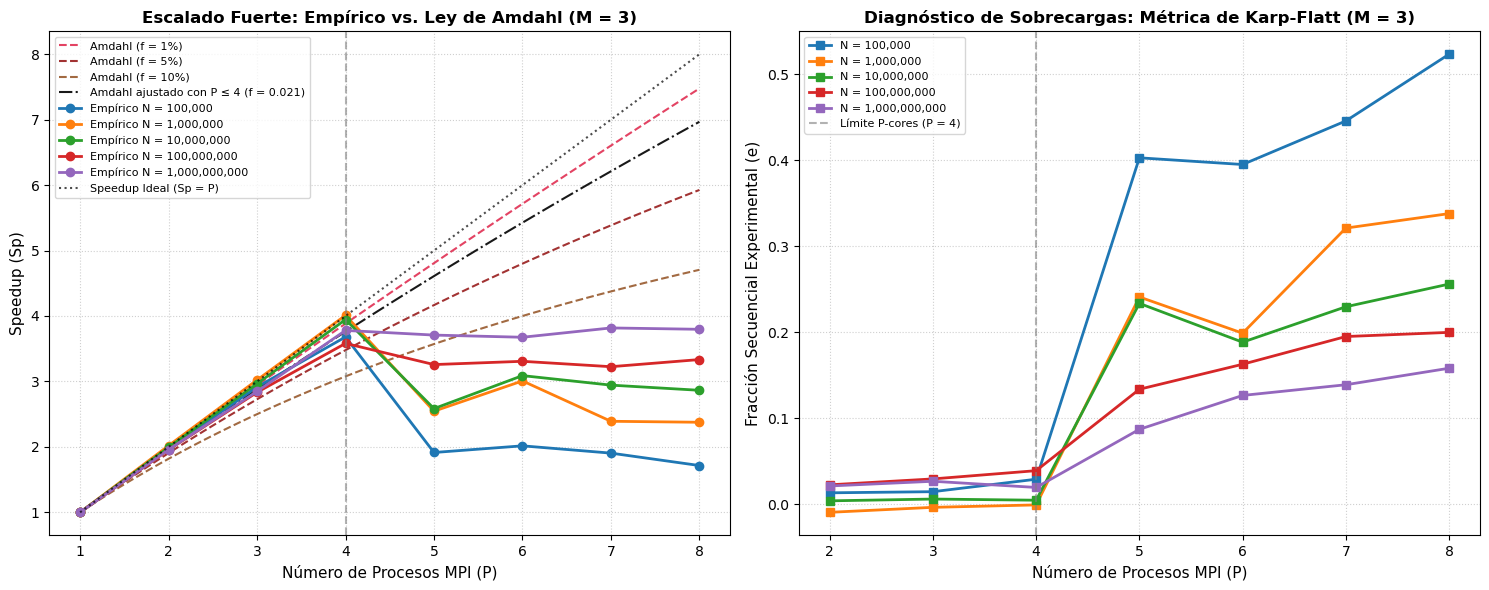

In [12]:
# ==============================================================================
# PASO 5.2: Speedup Empírico vs. Ley de Amdahl vs. Métrica de Karp-Flatt (M = 3)
# ==============================================================================
# Se usa solo M = 3: el costo por iteración no depende de M (T1 por M difiere < 0.25 %),
# y mezclar los cuatro M dibujaría cuatro puntos por cada P.

M_AMDAHL = 3

def amdahl_speedup(p, f):
    """Speedup teórico según la Ley de Amdahl para una fracción secuencial f."""
    return 1.0 / (f + (1.0 - f) / p)

def karp_flatt(speedup, p):
    """Fracción secuencial experimental 'e' según Karp-Flatt."""
    if p == 1:
        return 0.0
    return ((1.0 / speedup) - (1.0 / p)) / (1.0 - (1.0 / p))

df_m3 = df_agg[df_agg['M'] == M_AMDAHL].copy()
df_m3['karp_flatt'] = df_m3.apply(lambda row: karp_flatt(row['speedup'], row['n_procesos']), axis=1)

print(f"--- Karp-Flatt e(P), M = {M_AMDAHL} (filas = N, columnas = P) ---")
display(df_m3.pivot(index='N', columns='n_procesos', values='karp_flatt').drop(columns=1).round(3))

# Ajuste de f con los procesos dentro de los P-cores (P = 2..4) para N = 10^9
f_ajuste = df_m3[(df_m3['N'] == 1_000_000_000) & (df_m3['n_procesos'].between(2, 4))]['karp_flatt'].median()
print(f"\nFracción secuencial ajustada con P = 2..4 (N = 10^9): f ≈ {f_ajuste:.3f}")
print(f"Amdahl con ese f predice S_8 = {amdahl_speedup(8, f_ajuste):.2f}; "
      f"el dato empírico es S_8 = "
      f"{df_m3[(df_m3['N'] == 1_000_000_000) & (df_m3['n_procesos'] == 8)]['speedup'].iloc[0]:.2f}")

valores_P = np.array(sorted(df_m3['n_procesos'].unique()))
P_continuo = np.linspace(1, max(valores_P), 100)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# PANEL 1: Speedup empírico vs. curvas de Amdahl
for f_val, col in zip([0.01, 0.05, 0.10], ['crimson', 'darkred', 'saddlebrown']):
    ax1.plot(P_continuo, amdahl_speedup(P_continuo, f_val), linestyle='--', color=col, alpha=0.8,
             label=f'Amdahl (f = {int(f_val * 100)}%)')
ax1.plot(P_continuo, amdahl_speedup(P_continuo, f_ajuste), linestyle='-.', color='black', alpha=0.9,
         label=f'Amdahl ajustado con P ≤ 4 (f = {f_ajuste:.3f})')

valores_N = sorted(df_m3['N'].unique())
for n_val in valores_N:
    sub = df_m3[df_m3['N'] == n_val].sort_values('n_procesos')
    ax1.plot(sub['n_procesos'], sub['speedup'], marker='o', linewidth=2, label=f'Empírico N = {n_val:,}')

ax1.plot(valores_P, valores_P, linestyle=':', color='black', alpha=0.7, label='Speedup Ideal (Sp = P)')
ax1.axvline(x=4, color='gray', linestyle='--', alpha=0.6)
ax1.set_xlabel('Número de Procesos MPI (P)', fontsize=11)
ax1.set_ylabel('Speedup (Sp)', fontsize=11)
ax1.set_title(f'Escalado Fuerte: Empírico vs. Ley de Amdahl (M = {M_AMDAHL})', fontsize=12, fontweight='bold')
ax1.set_xticks(valores_P)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(fontsize=8, loc='upper left')

# PANEL 2: Métrica de Karp-Flatt
for n_val in valores_N:
    sub = df_m3[(df_m3['N'] == n_val) & (df_m3['n_procesos'] > 1)].sort_values('n_procesos')
    ax2.plot(sub['n_procesos'], sub['karp_flatt'], marker='s', linewidth=2, label=f'N = {n_val:,}')

ax2.axvline(x=4, color='gray', linestyle='--', alpha=0.6, label='Límite P-cores (P = 4)')
ax2.set_xlabel('Número de Procesos MPI (P)', fontsize=11)
ax2.set_ylabel('Fracción Secuencial Experimental (e)', fontsize=11)
ax2.set_title(f'Diagnóstico de Sobrecargas: Métrica de Karp-Flatt (M = {M_AMDAHL})', fontsize=12, fontweight='bold')
ax2.set_xticks(valores_P[valores_P > 1])
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(fontsize=8, loc='upper left')

plt.tight_layout()
plt.savefig('grafico_amdahl_vs_karp_flatt.png', dpi=300)
plt.show()


### 3. Interpretación Comparativa de Resultados (M = 3)

1. **Ajuste con la Ley de Amdahl: solo dentro de los P-cores.**
* Para $P \le 4$ (con $N = 10^9$) la curva empírica se ajusta a una fracción secuencial aparente de $f \approx 0.02$ (valor de la celda anterior). La ley describe bien ese tramo.
* Para $P > 4$ **no se sostiene**: con $f = 1\%$, Amdahl predice $S_8 \approx 7.5$, y el dato es $S_8 \approx 3.8$. Con el $f$ ajustado en $P \le 4$ también sobreestima.
* Con granularidad fina ($N = 10^5$) la curva se separa de Amdahl ya en $P = 5$ ($S_5 \approx 1.9$).

2. **Qué aporta la métrica de Karp-Flatt.**
* La Ley de Amdahl supone una fracción secuencial $f$ constante. Si $e(P)$ **no** es constante, la pérdida de eficiencia no proviene de una sección secuencial del código.
* Resultado: $e(P)$ es pequeño y casi constante para $P \le 4$ (entre $-0.01$ y $0.04$; los valores levemente negativos son ruido de medición) y **sube escalonadamente en $P = 5$** para todos los $N$ (con $N = 10^9$: de $\approx 0.02$ a $\approx 0.09$; con $N = 10^5$: de $\approx 0.03$ a $\approx 0.40$). Con $N = 10^9$ sigue creciendo hasta $\approx 0.16$ en $P = 8$.
* El salto coincide con el paso de P-cores a E-cores, lo que apunta a **desbalance de carga por núcleos heterogéneos**. Es coherente con el análisis del apartado 5.1 y con el hecho de que el overhead medido ($T_p - T_1/P$) crece en proporción a $N$, algo que no haría un costo fijo de comunicación.
* La inicialización de MPI y la creación de procesos **no** forman parte del tiempo medido. Con $N$ pequeño ($T_p \approx 0.1$ ms) la latencia de la reducción puede contribuir, pero con estos datos no se puede separar de la heterogeneidad: harían falta tiempos por rank.


## Paso 6.1: Carga, Agregación y Métricas del Clúster (Corrida Espejo)

En esta etapa se procesan los resultados provenientes de la ejecución en el clúster de alto rendimiento (nodo con procesadores AMD EPYC 7B12, arquitectura x86_64). Corresponde a la **Fase A (Corrida Espejo)**, ejecutada bajo exactamente las mismas combinaciones de variables que en la Mac M1 ($N \in \{10^5, 10^6, 10^7, 10^8, 10^9\}$, $P \in [1, 8]$ y $M \in \{3, 5, 10, 50\}$), ajustada a 5 repeticiones por punto de muestreo para un total estricto de **800 registros** ($5 \text{ valores de } N \times 8 \text{ procesos } \times 4 \text{ configuraciones de } M \times 5 \text{ repeticiones} = 800$).


In [13]:
# ==============================================================================
# PASO 6.1: Carga y Procesamiento de Datos del Clúster (800 Registros)
# ==============================================================================

csv_cluster_path = "datos/resultados_cluster_v2.csv"

print(f"Cargando datos del clúster desde: {csv_cluster_path}...")

# 1. Carga defensiva con tipos explícitos
try:
    df_cluster = pd.read_csv(
        csv_cluster_path,
        dtype={
            "n_procesos": "int32",
            "N": "int64",
            "M": "int32",
            "tiempo": "float64",
            "victorias_cambiando": "int64",
            "victorias_manteniendo": "int64",
            "p_empirico": "float64",
            "p_teorico": "float64",
            "error_abs": "float64",
            "semilla": "uint64",
        },
    )
    print(f"✓ Carga exitosa. Total de registros leídos: {len(df_cluster)}")
except FileNotFoundError:
    print(f"❌ Archivo '{csv_cluster_path}' no encontrado.")
    df_cluster = None

if df_cluster is not None:
    # Verificación del volumen de datos (Corrida Espejo: 800 registros)
    n_esperado = 800
    if len(df_cluster) == n_esperado:
        print(
            "✓ Verificación del dataset: Registros exactos coinciden con la corrida espejo (800 filas)."
        )
    else:
        print(
            f"⚠ Nota: Se registraron {len(df_cluster)} filas (esperadas: {n_esperado})."
        )

    # 2. Agregación Estadística por Medianas (agrupando por N, P y M)
    df_cluster_agg = (
        df_cluster.groupby(["N", "n_procesos", "M"])
        .agg(
            Tp=("tiempo", "median"),
            error_abs_mediana=("error_abs", "median"),
            p_empirico_mediana=("p_empirico", "median"),
        )
        .reset_index()
    )

    # 3. Extracción de T1 por cada par (N, M)
    df_t1_cluster = df_cluster_agg[df_cluster_agg["n_procesos"] == 1][
        ["N", "M", "Tp"]
    ].rename(columns={"Tp": "T1"})
    df_cluster_agg = pd.merge(
        df_cluster_agg, df_t1_cluster, on=["N", "M"], how="left"
    )

    # 4. Cálculo de Métricas HPC
    df_cluster_agg["speedup"] = df_cluster_agg["T1"] / df_cluster_agg["Tp"]
    df_cluster_agg["eficiencia"] = (
        df_cluster_agg["speedup"] / df_cluster_agg["n_procesos"]
    )

    print("\n--- Muestreo de Métricas Calculadas (Clúster, M=3) ---")
    display(df_cluster_agg[df_cluster_agg["M"] == 3].head(10))

Cargando datos del clúster desde: datos/resultados_cluster_v2.csv...
✓ Carga exitosa. Total de registros leídos: 800
✓ Verificación del dataset: Registros exactos coinciden con la corrida espejo (800 filas).

--- Muestreo de Métricas Calculadas (Clúster, M=3) ---


,N,n_procesos,M,Tp,error_abs_mediana,p_empirico_mediana,T1,speedup,eficiencia
0,100000,1,3,0.003033,0.001293,0.667430,0.003033,1.000000,1.000000
4,100000,2,3,0.001526,0.001243,0.666510,0.003033,1.987549,0.993775
8,100000,3,3,0.001020,0.000797,0.667090,0.003033,2.973529,0.991176
12,100000,4,3,0.000778,0.001067,0.665730,0.003033,3.898458,0.974614
16,100000,5,3,0.000626,0.000463,0.667130,0.003033,4.845048,0.969010
20,100000,6,3,0.000520,0.000527,0.666140,0.003033,5.832692,0.972115
24,100000,7,3,0.000462,0.000583,0.667250,0.003033,6.564935,0.937848
28,100000,8,3,0.000394,0.000547,0.666120,0.003033,7.697970,0.962246
32,1000000,1,3,0.030197,0.000469,0.666662,0.030197,1.000000,1.000000
36,1000000,2,3,0.015131,0.000347,0.666546,0.030197,1.995704,0.997852


## Paso 6.1b: Validación Estocástica del Clúster

Se repite sobre los datos del clúster (800 corridas, 5 repeticiones por $(M, N, P)$) el mismo procedimiento del Paso 6: unicidad de semillas, criterio $Z$ y test de sesgo por $(M, N)$. Con 5 repeticiones, cada celda $(M, N)$ tiene $n = 40$ corridas (frente a $n = 80$ en la Mac), por lo que el test es menos potente. Se grafica el $\bar{z}$ de ambas plataformas superpuestas.


==================== Clúster (AMD EPYC 7B12) ====================
--- Validación de Semillas ---
Total de corridas registradas: 800 | semillas únicas: 800
✓ ÉXITO: todas las corridas tienen semillas distintas.

--- Criterio Z por corrida ---
Corridas con |z| < 2: 95.00% (esperado ≈ 95%)

--- Test de sesgo por (M, N): t = z_medio · √n ---
Celdas (M, N): 20 | con |t| > 2: 0 (esperado por azar ≈ 0.9) | con |t| > 3: 0 (esperado ≈ 0.05) | máx |t| = 1.55


n  z_medio  pct_z_negativo  pct_dentro_z2      t
M  N                                                            
3  100000      40    0.011            47.5           97.5  0.070
   1000000     40    0.009            52.5           97.5  0.059
   10000000    40    0.229            47.5           92.5  1.448
   100000000   40   -0.231            67.5           90.0 -1.458
   1000000000  40   -0.029            45.0           87.5 -0.184
5  100000      40   -0.015            50.0           97.5 -0.096
   1000000     40    0.246            35.0           97.5  1.554
   10000000    40   -0.081            50.0           95.0 -0.510
   100000000   40   -0.014            62.5           97.5 -0.087
   1000000000  40    0.123            52.5           95.0  0.779
10 100000      40    0.022            47.5           95.0  0.137
   1000000     40   -0.045            45.0           97.5 -0.282
   10000000    40   -0.052            50.0           97.5 -0.330
   100000000   40   -0.063            50.0           92.5 -0.399
   1000000000  40   -0.019            52.5           95.0 -0.122
50 100000      40    0.108            45.0           97.5  0.686
   1000000     40    0.136            42.5          100.0  0.858
   10000000    40   -0.036            57.5           92.5 -0.225
   100000000   40   -0.100            55.0           92.5 -0.634
   1000000000  40   -0.093            50.0           92.5 -0.588

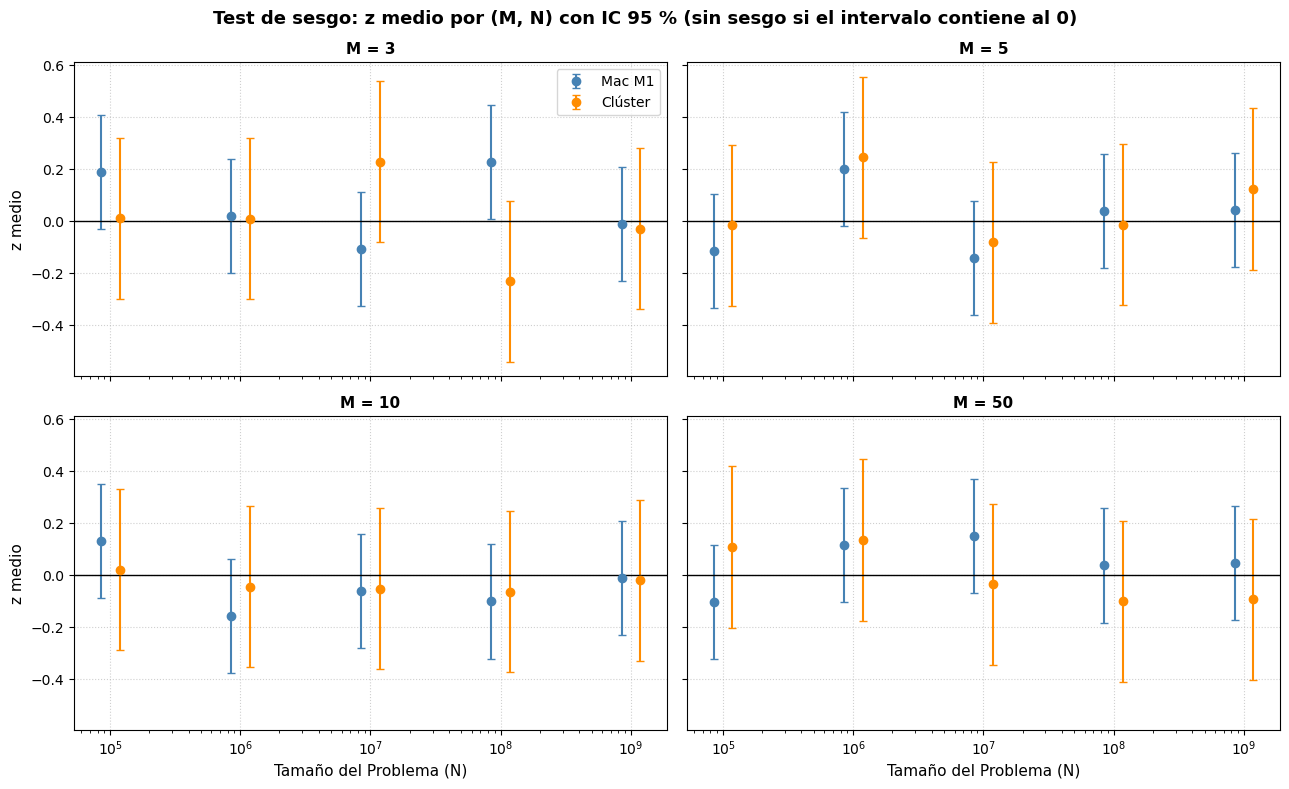

In [14]:
# ==============================================================================
# PASO 6.1b: Validación estocástica del clúster y comparación con la Mac
# ==============================================================================
if df_cluster is not None:
    tabla_cluster = validacion_estocastica(df_cluster, 'Clúster (AMD EPYC 7B12)')
    grafico_sesgo({'Mac M1': tabla_mac, 'Clúster': tabla_cluster}, 'grafico_sesgo_z_mac_vs_cluster.png')
else:
    print("Datos del clúster no disponibles: se omite la validación.")


### Interpretación de la validación estocástica del clúster

**Conclusión: el clúster reproduce el resultado de la Mac; no hay evidencia de sesgo.**

* **Semillas y criterio Z:** las 800 semillas son distintas y la tasa con $\vert z \vert < 2$ es 95.00 %, igual a la esperada.
* **Test de sesgo por $(M, N)$:** ninguna de las 20 celdas tiene $\vert t \vert > 2$ (máximo $1.55$); se esperaba $\approx 0.9$. La cobertura por celda va de 87.5 % a 100 %; la menor ($M = 3$, $N = 10^9$: 5 de 40 corridas fuera) tiene una probabilidad de $\approx 5\,\%$ por azar, y entre 20 celdas es esperable que alguna ocurra ($\approx 63\,\%$). Esa celda tiene $\bar{z} = -0.03$, por lo que no indica sesgo.
* **Sin signo sistemático:** 8 de las 20 medias $\bar{z}$ son positivas.
* **Con $N = 10^9$:** $t = -0.18,\ 0.78,\ -0.12,\ -0.59$ para $M = 3, 5, 10, 50$. Para $M = 3$, el intervalo de confianza del 95 % de $\bar{z}$ es $[-0.34, +0.28]$, mientras que el sesgo anterior implicaba $\bar{z} \approx -2.7$.
* **Comparación con la Mac:** todos los intervalos del clúster contienen al 0; el único intervalo de la Mac que apenas lo excluye ($M = 3$, $N = 10^8$, positivo) no se repite en el clúster, donde esa celda tiene signo opuesto ($t = -1.46$). Eso es lo esperable si se trata de fluctuación aleatoria y no de un efecto de la plataforma. **Salvedad:** el clúster tiene $n = 40$ por celda (la mitad que la Mac), por lo que el test es menos potente: detecta sesgos de $\bar{z} \gtrsim 0.5$, pero no menores.
* **Resultado:** con el mismo generador, Mac y clúster validan la frecuencia relativa contra la teoría para los cuatro valores de $M$.


## Paso 6.2: Comparación Cruzada Arquitectónica (Mac M1 vs. Clúster AMD EPYC)

### 1. Marco de Comparación Heterogénea

Para evaluar el comportamiento del algoritmo de Monte Carlo ante distintas arquitecturas de hardware, se realiza un análisis comparativo entre:

* **Apple Silicon M1 (ARM64 Asimétrico):** Arquitectura SoC heterogénea basada en 4 núcleos de alto rendimiento (*P-cores*, Firestorm) y 4 núcleos de alta eficiencia (*E-cores*, Icestorm).
* **AMD EPYC 7B12 (x86_64 Homogéneo):** Procesador de servidor con núcleos x86 idénticos de alto rendimiento y arquitectura simétrica de memoria compartida/NUMA.

### 2. Diferencias Clave de Comportamiento

1. **Velocidad Mononúcleo ($T_1$):** con este código, la Mac M1 es unas **17 veces más rápida por núcleo**: con $N = 10^9$, $T_1 \approx 1.79$ s en la Mac frente a $T_1 \approx 30.1$ s en el clúster (≈ 1.8 ns frente a ≈ 30 ns por iteración). El IPC por sí solo no alcanza para explicar un factor tan grande. **Hipótesis (no medida):** las dos divisiones de 64 bits de `% puertas` por iteración son lentas en la microarquitectura Zen 2 y rápidas en el M1.
2. **Escalabilidad Paralela ($P > 4$):**
* En **Mac M1**, al superar $P = 4$, el planificador del SO asigna procesos a los *E-cores*, induciendo el **efecto convoy** durante las llamadas a `MPI_Reduce` (los procesos en *P-cores* quedan esperando al proceso más lento en el *E-core*), lo que genera una caída brusca de la eficiencia ($E_p$).
* En el **Clúster**, al ser una arquitectura **100% homogénea**, cada proceso adicional cuenta con capacidad de cómputo simétrica. La curva de *Speedup* se mantiene prácticamente lineal en todo el rango $P \in [1, 8]$, con una eficiencia paralela $E_p \approx 99.8\%$ para $N = 10^9$ (entre 94 % y 99 % para $N = 10^5$). La corrida espejo llegó hasta $P = 8$; el diagnóstico previo mostró $E_p \approx 0.99$ hasta $P = 12$ (cuota del contenedor).

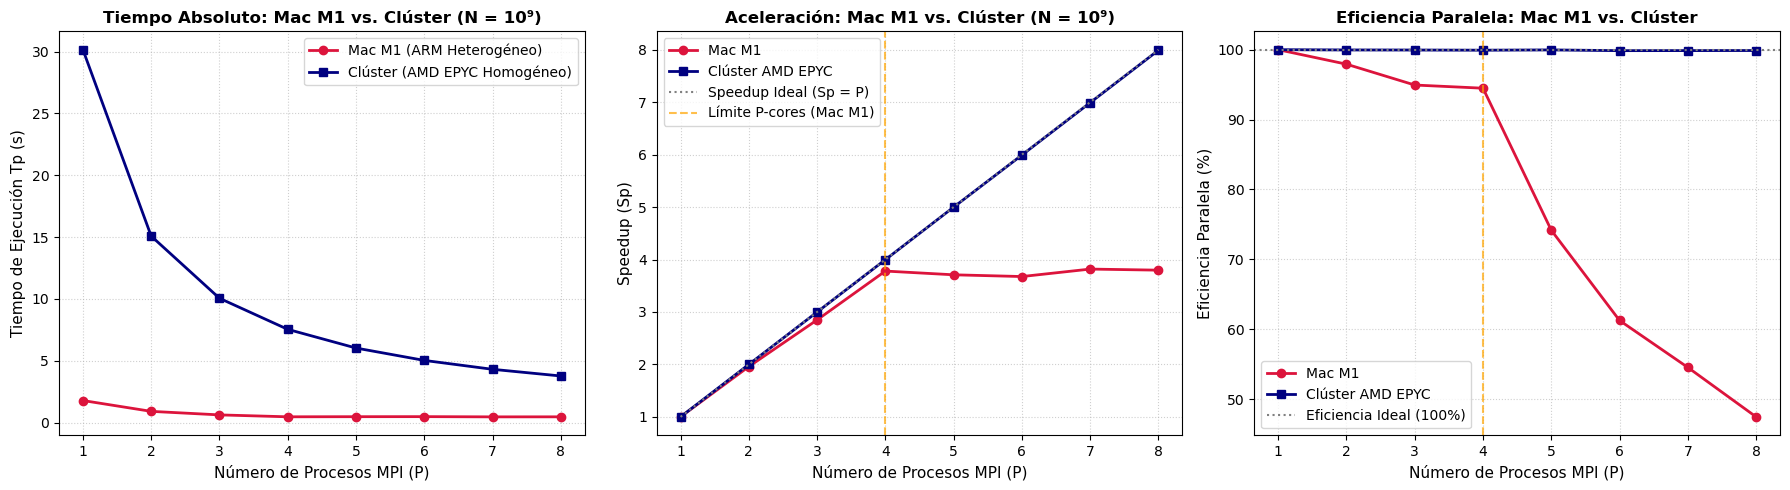

In [15]:
# ==============================================================================
# PASO 6.2: Gráficos Comparativos Mac M1 vs. Clúster (AMD EPYC) para N = 10⁹, M = 3
# ==============================================================================

# Filtrar subconjuntos para N = 10^9 y M = 3 en ambas plataformas
N_target = 1000000000
M_target = 3

sub_mac = df_agg[(df_agg["N"] == N_target) & (df_agg["M"] == M_target)].sort_values(
    "n_procesos"
)
sub_cluster = df_cluster_agg[
    (df_cluster_agg["N"] == N_target) & (df_cluster_agg["M"] == M_target)
].sort_values("n_procesos")

procesos = sub_mac["n_procesos"]

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: Tiempo de Ejecución Absoluto (Tp)
ax1.plot(
    procesos,
    sub_mac["Tp"],
    marker="o",
    linewidth=2,
    color="crimson",
    label="Mac M1 (ARM Heterogéneo)",
)
ax1.plot(
    procesos,
    sub_cluster["Tp"],
    marker="s",
    linewidth=2,
    color="navy",
    label="Clúster (AMD EPYC Homogéneo)",
)
ax1.set_xlabel("Número de Procesos MPI (P)", fontsize=11)
ax1.set_ylabel("Tiempo de Ejecución Tp (s)", fontsize=11)
ax1.set_title(
    "Tiempo Absoluto: Mac M1 vs. Clúster (N = 10⁹)",
    fontsize=12,
    fontweight="bold",
)
ax1.set_xticks(procesos)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend()

# Panel 2: Speedup Comparativo (Sp)
ax2.plot(
    procesos,
    sub_mac["speedup"],
    marker="o",
    linewidth=2,
    color="crimson",
    label="Mac M1",
)
ax2.plot(
    procesos,
    sub_cluster["speedup"],
    marker="s",
    linewidth=2,
    color="navy",
    label="Clúster AMD EPYC",
)
ax2.plot(
    procesos,
    procesos,
    linestyle=":",
    color="gray",
    label="Speedup Ideal (Sp = P)",
)
ax2.axvline(
    x=4,
    color="orange",
    linestyle="--",
    alpha=0.7,
    label="Límite P-cores (Mac M1)",
)
ax2.set_xlabel("Número de Procesos MPI (P)", fontsize=11)
ax2.set_ylabel("Speedup (Sp)", fontsize=11)
ax2.set_title(
    "Aceleración: Mac M1 vs. Clúster (N = 10⁹)", fontsize=12, fontweight="bold"
)
ax2.set_xticks(procesos)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend()

# Panel 3: Eficiencia Paralela (Ep)
ax3.plot(
    procesos,
    sub_mac["eficiencia"] * 100,
    marker="o",
    linewidth=2,
    color="crimson",
    label="Mac M1",
)
ax3.plot(
    procesos,
    sub_cluster["eficiencia"] * 100,
    marker="s",
    linewidth=2,
    color="navy",
    label="Clúster AMD EPYC",
)
ax3.axhline(
    y=100, linestyle=":", color="gray", label="Eficiencia Ideal (100%)"
)
ax3.axvline(x=4, color="orange", linestyle="--", alpha=0.7)
ax3.set_xlabel("Número de Procesos MPI (P)", fontsize=11)
ax3.set_ylabel("Eficiencia Paralela (%)", fontsize=11)
ax3.set_title(
    "Eficiencia Paralela: Mac M1 vs. Clúster", fontsize=12, fontweight="bold"
)
ax3.set_xticks(procesos)
ax3.grid(True, linestyle=":", alpha=0.6)
ax3.legend()

plt.tight_layout()
plt.savefig("grafico_comparativo_mac_vs_cluster.png", dpi=300)
plt.show()

## Paso 6.3: Síntesis y Conclusiones del Análisis en Clúster

| Dimension de Análisis | Mac M1 (Apple Silicon) | Clúster (AMD EPYC 7B12) | Diagnóstico Técnico |
| --- | --- | --- | --- |
| **Topología de CPU** | Asimétrica (4 P-cores + 4 E-cores) | Simétrica (x86_64 multinúcleo) | La asimetría de núcleos altera las curvas de aceleración paralela. |
| **Punto Óptimo ($P$)** | $P = 4$ procesos MPI | $P = 8$ (máximo medido en la corrida espejo; $E_p \approx 0.99$ hasta $P = 12$ en el diagnóstico) | La saturación de P-cores impone un tope práctico en el chip M1. |
| **Comportamiento en $P > 4$** | Caída de eficiencia (efecto convoy) | Escalado lineal sostenido ($E_p \approx 99.8\%$ con $N = 10^9$) | La simetría de procesador previene la degradación por sincronización. |
| **Tiempo secuencial $T_1$ ($N = 10^9$)** | ≈ 1.79 s | ≈ 30.1 s | La Mac es ≈ 17 veces más rápida por núcleo con este código; causa no medida (hipótesis: divisiones de 64 bits en Zen 2). |
| **Efecto del Tamaño ($N$)** | Escalado casi ideal hasta $P = 4$ desde $N \approx 10^6$; para $P > 4$ la eficiencia mejora con $N$ sin llegar al ideal | $E_p \ge 0.94$ incluso con $N = 10^5$ | En el clúster el costo por iteración (≈ 30 ns) hace que $N = 10^5$ ya dure ≈ 3 ms con $P = 1$, lo que diluye la sobrecarga de sincronización; en la Mac, con ≈ 1.8 ns por iteración, la misma carga dura ≈ 0.2 ms. |

# Experimento 3: Barrido continuo de $P = 1 \dots 28$ en el clúster (Ley de Amdahl)

**Plataforma:** Clúster de la Facultad (AMD EPYC 7B12, nodo único), sesión con recurso de **192 GB de RAM y 48 cores**, la opción mínima que permite $P = 28$ (la RAM no interviene: el programa usa megabytes).
**Script:** `scripts/run_amdahl.sh` (repetición como bucle exterior, compilación con `-O2`, el mismo `monty_hall.c` de los demás experimentos). El script escribe `amdahl_<fecha>.csv`; el archivo se renombró a `resultados_amdahl.csv`.
**Diseño:** $N \in \{10^4, 10^5, \dots, 10^9\}$ × $P = 1 \dots 28$ (sin huecos, requisito de cátedra) × 3 repeticiones, con $M = 3$: 504 corridas.

**Limitaciones del diseño:** (1) 3 repeticiones por punto; (2) el tiempo se registra con resolución de 1 µs, lo que afecta a $N \le 10^5$ (con $T_p$ de decenas a cientos de µs); (3) no se registraron `cpu.max`, la garantía de cores de ese recurso ni la carga del nodo durante la corrida. Por eso, los puntos óptimos $P^*$ de $N \le 10^5$ se consideran **orientativos**.

## Paso A1: Carga, Validación e Inspección de Datos

En esta etapa se importan los resultados del barrido continuo ($P \in [1, 28]$ y $N \in [10^4, 10^9]$) almacenados en `datos/resultados_amdahl.csv`. Se aplica un esquema de lectura con tipos numéricos explícitos para prevenir problemas de precisión o desbordamiento, y se verifica la presencia de todas las variables exportadas por el simulador MPI.


In [16]:
# ==============================================================================
# PASO A1: Carga y Verificación del Archivo de Resultados
# ==============================================================================

csv_path = 'datos/resultados_amdahl.csv'
print(f"Cargando dataset: {csv_path} ...")

try:
    df_amdahl = pd.read_csv(
        csv_path,
        dtype={
            'n_procesos': 'int32',
            'tiempo': 'float64',
            'N': 'int64',
            'M': 'int32',
            'victorias_cambiando': 'int64',
            'victorias_manteniendo': 'int64',
            'p_empirico': 'float64',
            'p_teorico': 'float64',
            'error_abs': 'float64',
            'semilla': 'uint64'
        }
    )
    print("✓ Dataset cargado exitosamente.\n")
except FileNotFoundError:
    print(f"❌ Error: No se encontró el archivo '{csv_path}'. Verifica que la corrida de bash haya finalizado.")
    df_amdahl = None

if df_amdahl is not None:
    columnas_esperadas = [
        'n_procesos', 'tiempo', 'N', 'M', 
        'victorias_cambiando', 'victorias_manteniendo', 
        'p_empirico', 'p_teorico', 'error_abs', 'semilla'
    ]
    
    faltantes = [col for col in columnas_esperadas if col not in df_amdahl.columns]
    if faltantes:
        raise ValueError(f"Faltan columnas en el CSV: {faltantes}")
    
    nulos = df_amdahl.isnull().sum().sum()
    print(f"✓ Control de integridad: {nulos} valores nulos detectados.")
    
    print("\n--- Resumen del Barrido Amdahl ---")
    print(f"Total de ejecuciones registradas : {len(df_amdahl)}")
    print(f"Valores de N evaluados           : {sorted(df_amdahl['N'].unique())}")
    print(f"Rango continuo de P evaluados    : {min(df_amdahl['n_procesos'])} a {max(df_amdahl['n_procesos'])}")
    reps_pt = df_amdahl.groupby(['N', 'n_procesos']).size()
    print(f"Repeticiones por punto (N, P)    : mín = {reps_pt.min()}, máx = {reps_pt.max()}")
    
    display(df_amdahl.head())


Cargando dataset: datos/resultados_amdahl.csv ...
✓ Dataset cargado exitosamente.

✓ Control de integridad: 0 valores nulos detectados.

--- Resumen del Barrido Amdahl ---
Total de ejecuciones registradas : 504
Valores de N evaluados           : [10000, 100000, 1000000, 10000000, 100000000, 1000000000]
Rango continuo de P evaluados    : 1 a 28
Repeticiones por punto (N, P)    : mín = 3, máx = 3


,n_procesos,tiempo,N,M,victorias_cambiando,victorias_manteniendo,p_empirico,p_teorico,error_abs,semilla
0,1,0.000304,10000,3,6681,3319,0.6681,0.666667,0.001433,1923156007627825105
1,2,0.000163,10000,3,6717,3283,0.6717,0.666667,0.005033,1923156008093544451
2,3,0.000118,10000,3,6688,3312,0.6688,0.666667,0.002133,1923156008662838583
3,4,0.000093,10000,3,6663,3337,0.6663,0.666667,0.000367,1923156009166755001
4,5,0.000082,10000,3,6622,3378,0.6622,0.666667,0.004467,1923156009757304630


## Paso A2: Agregación Estadística por Medianas y Extracción de $T_1$

Para filtrar fluctuaciones térmicas, interrupciones del kernel y jitter del sistema operativo, se agrupan las corridas por el par $(N, P)$ extrayendo la **mediana estadística** del tiempo de ejecución ($T_p$) y del error absoluto.

Posteriormente, se extrae el tiempo base secuencial $T_1 = T_p(P=1)$ correspondiente a cada tamaño de problema $N$.


In [17]:
# ==============================================================================
# PASO A2: Agregación Estadística por Medianas y Extracción de T1
# ==============================================================================

# 1. Agrupar por N y n_procesos obteniendo las medianas
df_agg_am = df_amdahl.groupby(['N', 'n_procesos']).agg(
    Tp=('tiempo', 'median'),
    error_abs_mediana=('error_abs', 'median'),
    M=('M', 'first')
).reset_index()

# 2. Ordenar de forma determinista para garantizar alineación
df_agg_am = df_agg_am.sort_values(by=['N', 'n_procesos']).reset_index(drop=True)

# 3. Extraer T1 (tiempo secuencial con P = 1) para cada N
df_t1_am = df_agg_am[df_agg_am['n_procesos'] == 1][['N', 'Tp']].rename(columns={'Tp': 'T1'})

# 4. Unir T1 al DataFrame consolidado
df_agg_am = pd.merge(df_agg_am, df_t1_am, on='N', how='left')

print("--- Tiempos Secuenciales Base (T1) ---")
for _, row in df_t1_am.iterrows():
    print(f"N = 10^{int(np.log10(row['N'])):<2d} ({int(row['N']):>10,d}) | T1 = {row['T1']:.6f} seg")

display(df_agg_am.head(10))


--- Tiempos Secuenciales Base (T1) ---
N = 10^4  (    10,000) | T1 = 0.000304 seg
N = 10^5  (   100,000) | T1 = 0.003040 seg
N = 10^6  ( 1,000,000) | T1 = 0.030158 seg
N = 10^7  (10,000,000) | T1 = 0.301351 seg
N = 10^8  (100,000,000) | T1 = 3.015524 seg
N = 10^9  (1,000,000,000) | T1 = 30.141340 seg


,N,n_procesos,Tp,error_abs_mediana,M,T1
0,10000,1,0.000304,0.001433,3,0.000304
1,10000,2,0.000163,0.005033,3,0.000304
2,10000,3,0.000113,0.004667,3,0.000304
3,10000,4,0.000093,0.002233,3,0.000304
4,10000,5,0.000082,0.004467,3,0.000304
5,10000,6,0.000071,0.006167,3,0.000304
6,10000,7,0.000059,0.009433,3,0.000304
7,10000,8,0.000052,0.000467,3,0.000304
8,10000,9,0.000047,0.008767,3,0.000304
9,10000,10,0.000045,0.004167,3,0.000304


## Paso A3: Cálculo de Métricas de HPC e Identificación del Punto Óptimo $P^*$

Se derivan las métricas fundamentales de aceleración y eficiencia paralela:

$$S_p(N, P) = \frac{T_1(N)}{T_p(N, P)}, \qquad E_p(N, P) = \frac{S_p(N, P)}{P}$$

Asimismo, para cada tamaño de problema $N$, se identifica el punto óptimo $P^* = \arg\max_P S_p(N, P)$, lo que demuestra empíricamente cómo el codo de rendimiento se desplaza a mayor concurrencia a medida que escala $N$.


In [18]:
# ==============================================================================
# PASO A3: Métricas de Aceleración e Identificación de P*
# ==============================================================================

# 1. Calculo de Speedup y Eficiencia
df_agg_am['speedup'] = df_agg_am['T1'] / df_agg_am['Tp']
df_agg_am['eficiencia'] = df_agg_am['speedup'] / df_agg_am['n_procesos']

# 2. Extracción de P* (Punto de máximo Speedup para cada N)
idx_p_opt = df_agg_am.groupby('N')['speedup'].idxmax()
tabla_p_opt_am = df_agg_am.loc[idx_p_opt, ['N', 'n_procesos', 'Tp', 'T1', 'speedup', 'eficiencia']].copy()
tabla_p_opt_am = tabla_p_opt_am.rename(columns={'n_procesos': 'P*'})

print("==========================================================================")
print("DEMOSTRACIÓN DE AMDAHL: P* EN FUNCIÓN DE LA GRANULARIDAD N")
print("==========================================================================")
display(tabla_p_opt_am)


DEMOSTRACIÓN DE AMDAHL: P* EN FUNCIÓN DE LA GRANULARIDAD N


,N,P*,Tp,T1,speedup,eficiencia
14,10000,15,0.000038,0.000304,8.000000,0.533333
54,100000,27,0.000152,0.003040,20.000000,0.740741
83,1000000,28,0.001134,0.030158,26.594356,0.949798
111,10000000,28,0.010905,0.301351,27.634204,0.986936
139,100000000,28,0.108247,3.015524,27.857807,0.994922
167,1000000000,28,1.080941,30.141340,27.884353,0.995870


## Paso A3b: Overhead Medido y Modelo $T_p \approx T_1/P + c_0 + \alpha P$

Para entender por qué el speedup se estanca en los $N$ chicos, se calcula el **overhead** de cada punto, $T_p - T_1/P$ (lo que queda del tiempo medido si el cómputo se repartiera perfectamente), y se ajusta una recta $c_0 + \alpha P$ con los $N$ donde domina ($N = 10^4$ y $10^5$). Con ese modelo, $S(P) = T_1 / (T_1/P + c_0 + \alpha P)$ tiene un máximo en $P^* = \sqrt{T_1/\alpha}$. Se contrasta contra los datos, incluido un $N$ que **no** se usó en el ajuste ($10^6$), y se agrega la fracción secuencial experimental de Karp-Flatt a $P = 28$.


--- Overhead = Tp − T1/P (µs), mediana de las repeticiones ---


n_procesos,2,4,8,12,16,20,24,28
N,,,,,,,,
10000,11,17,14,31,30,39,47,43
100000,6,14,17,18,30,37,43,50
1000000,47,57,82,73,57,60,62,57
10000000,106,363,270,300,236,223,252,142
100000000,1570,1295,2296,1818,1425,567,580,550
1000000000,12268,22785,9943,9257,11073,4713,4252,4465



Ajuste (N = 10^4 y 10^5): overhead ≈ 6.0 µs + 1.54 µs · P   (R² = 0.82)

--- Modelo vs. observado, y Karp-Flatt a P = 28 ---


,P* modelo,S(28) modelo,S(28) observado,Karp-Flatt e(28)
N,,,,
10000,14.03629,5.06351,5.62963,0.14717
100000,44.38666,19.27080,19.11950,0.01720
1000000,139.80315,26.77732,26.59436,0.00196
10000000,441.92850,27.87263,27.63420,0.00049
100000000,1397.96754,27.98722,27.85781,0.00019
1000000000,4419.74252,27.99872,27.88435,0.00015


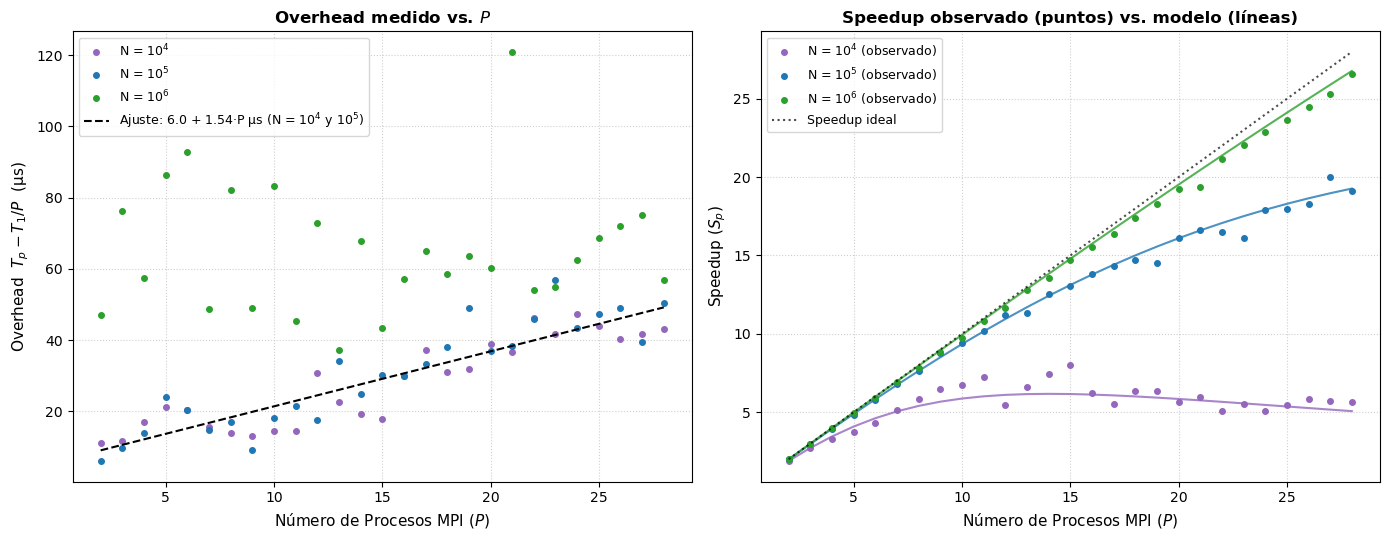

In [19]:
# ==============================================================================
# PASO A3b: Overhead medido (T_p − T_1/P) y modelo T_p ≈ T_1/P + c0 + alpha·P
# ==============================================================================

# Overhead en microsegundos por (N, P)
df_agg_am['overhead_us'] = (df_agg_am['Tp'] - df_agg_am['T1'] / df_agg_am['n_procesos']) * 1e6

P_MUESTRA = [2, 4, 8, 12, 16, 20, 24, 28]
tabla_ov = df_agg_am[df_agg_am['n_procesos'].isin(P_MUESTRA)].pivot(index='N', columns='n_procesos', values='overhead_us')
print("--- Overhead = Tp − T1/P (µs), mediana de las repeticiones ---")
display(tabla_ov.round(0).astype(int))

# Ajuste lineal overhead = c0 + alpha·P con los N de granularidad fina (N = 1e4 y 1e5), P = 2..28
fino = df_agg_am[(df_agg_am['N'].isin([10**4, 10**5])) & (df_agg_am['n_procesos'] >= 2)]
alpha_us, c0_us = np.polyfit(fino['n_procesos'], fino['overhead_us'], 1)
resid = fino['overhead_us'] - (c0_us + alpha_us * fino['n_procesos'])
r2 = 1 - (resid ** 2).sum() / ((fino['overhead_us'] - fino['overhead_us'].mean()) ** 2).sum()
print(f"\nAjuste (N = 10^4 y 10^5): overhead ≈ {c0_us:.1f} µs + {alpha_us:.2f} µs · P   (R² = {r2:.2f})")

def speedup_modelo(T1_us, p):
    return T1_us / (T1_us / p + c0_us + alpha_us * p)

filas = []
for n_val in sorted(df_agg_am['N'].unique()):
    T1_us = df_agg_am[(df_agg_am['N'] == n_val) & (df_agg_am['n_procesos'] == 1)]['Tp'].iloc[0] * 1e6
    f28 = df_agg_am[(df_agg_am['N'] == n_val) & (df_agg_am['n_procesos'] == 28)].iloc[0]
    s_obs = f28['speedup']
    filas.append({
        'N': int(n_val),
        'P* modelo': np.sqrt(T1_us / alpha_us),
        'S(28) modelo': speedup_modelo(T1_us, 28),
        'S(28) observado': s_obs,
        'Karp-Flatt e(28)': ((1 / s_obs) - (1 / 28)) / (1 - 1 / 28),
    })
print("\n--- Modelo vs. observado, y Karp-Flatt a P = 28 ---")
display(pd.DataFrame(filas).set_index('N').round(5))

# Figura: overhead vs P (izquierda) y speedup observado vs. modelo (derecha)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
P_eje = np.arange(2, 29)
for n_val, col in zip([10**4, 10**5, 10**6], ['tab:purple', 'tab:blue', 'tab:green']):
    sub = df_agg_am[(df_agg_am['N'] == n_val) & (df_agg_am['n_procesos'] >= 2)].sort_values('n_procesos')
    T1_us = df_agg_am[(df_agg_am['N'] == n_val) & (df_agg_am['n_procesos'] == 1)]['Tp'].iloc[0] * 1e6
    etiqueta = f'N = $10^{{{int(np.log10(n_val))}}}$'
    ax1.plot(sub['n_procesos'], sub['overhead_us'], 'o', color=col, markersize=4, label=etiqueta)
    ax2.plot(sub['n_procesos'], sub['speedup'], 'o', color=col, markersize=4, label=f'{etiqueta} (observado)')
    ax2.plot(P_eje, speedup_modelo(T1_us, P_eje), '-', color=col, alpha=0.8)
ax1.plot(P_eje, c0_us + alpha_us * P_eje, '--', color='black',
         label=f'Ajuste: {c0_us:.1f} + {alpha_us:.2f}·P µs (N = $10^4$ y $10^5$)')
ax1.set_xlabel('Número de Procesos MPI ($P$)', fontsize=11)
ax1.set_ylabel('Overhead  $T_p - T_1/P$  (µs)', fontsize=11)
ax1.set_title('Overhead medido vs. $P$', fontsize=12, fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(fontsize=9)
ax2.plot(P_eje, P_eje, ':', color='black', alpha=0.7, label='Speedup ideal')
ax2.set_xlabel('Número de Procesos MPI ($P$)', fontsize=11)
ax2.set_ylabel('Speedup ($S_p$)', fontsize=11)
ax2.set_title('Speedup observado (puntos) vs. modelo (líneas)', fontsize=12, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(fontsize=9, loc='upper left')
plt.tight_layout()
plt.savefig('grafico_amdahl_overhead_modelo.png', dpi=300)
plt.show()


### Interpretación del overhead y del modelo (Paso A3b)

* **El overhead crece con $P$ y casi no depende de $N$.** Con $N = 10^4$ y $10^5$ los valores son parecidos (p. ej., 11 y 6 µs con $P = 2$; 43 y 50 µs con $P = 28$) y aumentan aproximadamente de forma lineal: ajuste ≈ 6 µs + 1.54 µs·$P$ ($R^2 \approx 0.82$; el ruido de medianas de 3 repeticiones limita el ajuste).
* **El modelo se sostiene fuera de la muestra.** Con $N = 10^6$ (no usado en el ajuste) predice $S(28) \approx 26.8$ frente a $26.59$ observado (+0.7 %); con $N = 10^5$, $19.3$ frente a $19.12$ (+0.8 %). Con $N = 10^4$ subestima un 10 % ($5.1$ frente a $5.63$), el punto más ruidoso (tiempos de 32 a 60 µs).
* **Límite de la medición con $N = 10^6$:** a $P$ bajos su overhead aparente (47 a 93 µs) supera al del modelo porque la dispersión entre repeticiones (≈ 2 % de un $T_p$ de varios ms) es mayor que el overhead mismo; solo con $P$ alto, donde $T_p \approx 1$ ms, el overhead se vuelve medible (57 µs con $P = 28$, en línea con el ajuste).
* **Óptimo previsto:** $P^* \approx \sqrt{T_1/\alpha}$ da ≈ 14 para $N = 10^4$ (observado: 15) y ≈ 44 para $N = 10^5$ (fuera del barrido, por lo que el máximo observado en $P = 27$ es el final de una curva todavía creciente).
* **Karp-Flatt a $P = 28$:** $e = 0.147,\ 0.017,\ 0.0020,\ 0.0005,\ 0.0002,\ 0.00015$ para $N = 10^4 \dots 10^9$: la fracción secuencial efectiva se diluye al crecer el trabajo, como en una parte serial de tiempo aproximadamente fijo.
* **Salvedad:** el overhead medido agrupa la sincronización de la barrera, la reducción y el desfase de arranque de los procesos; con estos datos no se pueden separar.


## Paso A4.1: Curvas de Speedup vs. Procesos ($P = 1 \dots 28$)

Este gráfico evalúa el escalado fuerte continuo para $N \in [10^4, 10^9]$. Con $N \ge 10^6$ la curva es monótona creciente hasta $P = 28$ (eficiencia $\ge 0.95$). Con $N = 10^5$ el máximo observado está en $P = 27$ ($S \approx 20$) y con $N = 10^4$ en $P = 15$ ($S \approx 8$), tras lo cual el speedup se estanca o cae. **Los $P^*$ de $N \le 10^5$ son orientativos**: hay 3 repeticiones por punto y el reloj tiene resolución de 1 µs (con $N = 10^4$ los tiempos son de 32 a 60 µs); el modelo del Paso A3b describe esa forma con menos ruido.


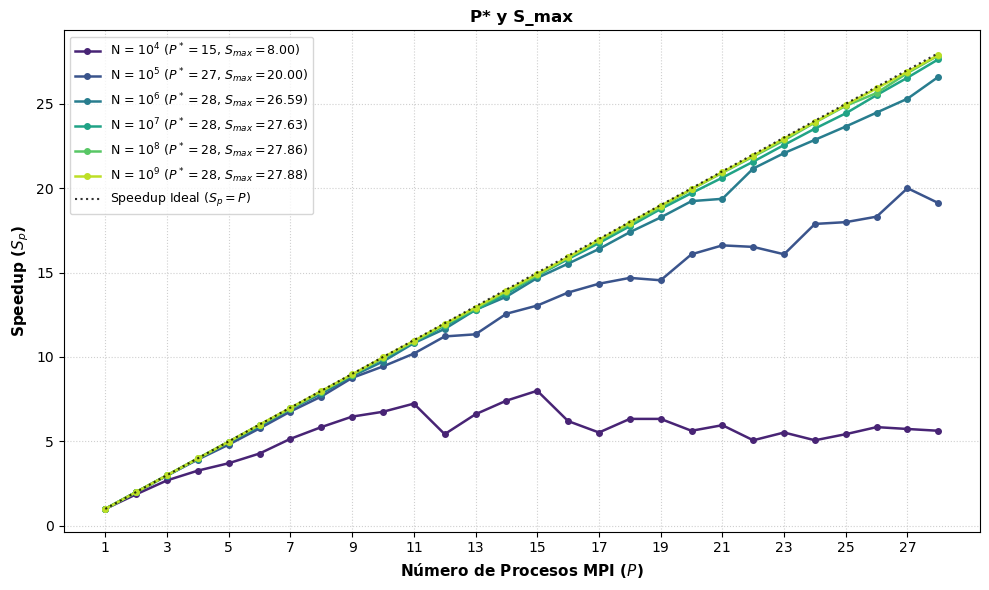

In [20]:
# ==============================================================================
# PASO A4.1: Gráfico 1 - Speedup vs. Procesos P (Demostración de Amdahl)
# ==============================================================================

plt.figure(figsize=(10, 6))

valores_N_am = sorted(df_agg_am['N'].unique())
valores_P_am = np.arange(1, 29)

colores_am = plt.cm.viridis(np.linspace(0.1, 0.9, len(valores_N_am)))

for i, n_val in enumerate(valores_N_am):
    subset = df_agg_am[df_agg_am['N'] == n_val].sort_values('n_procesos')
    p_opt = tabla_p_opt_am.loc[tabla_p_opt_am['N'] == n_val, 'P*'].values[0]
    sp_max = tabla_p_opt_am.loc[tabla_p_opt_am['N'] == n_val, 'speedup'].values[0]
    
    plt.plot(
        subset['n_procesos'], subset['speedup'], 
        marker='o', markersize=4, linewidth=1.8, color=colores_am[i],
        label=f'N = $10^{{{int(np.log10(n_val))}}}$ ($P^*={p_opt}$, $S_{{max}}={sp_max:.2f}$)'
    )

# Referencia Ideal
plt.plot(valores_P_am, valores_P_am, linestyle=':', color='black', alpha=0.8, label='Speedup Ideal ($S_p = P$)')

plt.xlabel('Número de Procesos MPI ($P$)', fontsize=11, fontweight='bold')
plt.ylabel('Speedup ($S_p$)', fontsize=11, fontweight='bold')
plt.title(r'P* y S_max', fontsize=12, fontweight='bold')
plt.xticks(range(1, 29, 2))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=9, loc='upper left')
plt.tight_layout()

plt.savefig('grafico_amdahl_speedup.png', dpi=300)
plt.show()


## Paso A4.2: Eficiencia Paralela vs. Procesos ($P$)

En esta figura se grafica la pérdida de eficiencia $E_p$ a medida que aumenta la concurrencia. Con $P = 28$: $E_p \approx 0.20$ ($N = 10^4$), $0.68$ ($N = 10^5$), $0.95$ ($N = 10^6$), $0.987$ ($N = 10^7$), $0.995$ ($N = 10^8$) y $0.996$ ($N = 10^9$). Muestra el paso de un régimen dominado por el overhead de sincronización y reducción ($N = 10^4$) a uno de aprovechamiento casi ideal del procesador ($N \ge 10^7$).


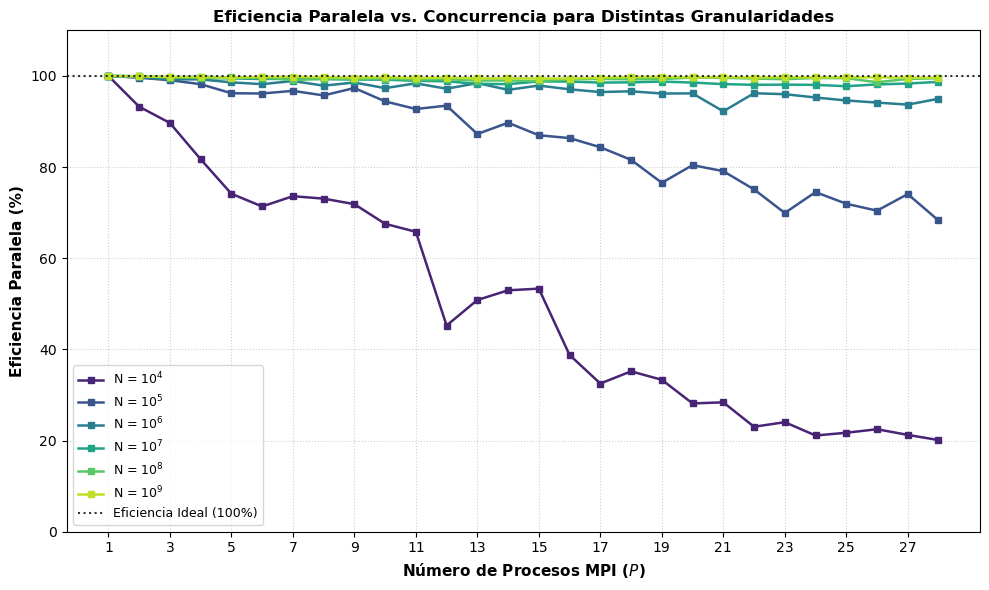

In [20]:
# ==============================================================================
# PASO A4.2: Gráfico 2 - Eficiencia Paralela vs. Procesos P
# ==============================================================================

plt.figure(figsize=(10, 6))

for i, n_val in enumerate(valores_N_am):
    subset = df_agg_am[df_agg_am['N'] == n_val].sort_values('n_procesos')
    plt.plot(
        subset['n_procesos'], subset['eficiencia'] * 100, 
        marker='s', markersize=4, linewidth=1.8, color=colores_am[i],
        label=f'N = $10^{{{int(np.log10(n_val))}}}$'
    )

plt.axhline(y=100, linestyle=':', color='black', alpha=0.8, label='Eficiencia Ideal (100%)')

plt.xlabel('Número de Procesos MPI ($P$)', fontsize=11, fontweight='bold')
plt.ylabel('Eficiencia Paralela (%)', fontsize=11, fontweight='bold')
plt.title('Eficiencia Paralela vs. Concurrencia para Distintas Granularidades', fontsize=12, fontweight='bold')
plt.xticks(range(1, 29, 2))
plt.ylim(0, 110)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=9, loc='lower left')
plt.tight_layout()

plt.savefig('grafico_amdahl_eficiencia.png', dpi=300)
plt.show()


## Paso A4.3: Convergencia Estocástica del Error de Monte Carlo ($O(1/\sqrt{N})$)

Se evalúa la precisión matemática del simulador contrastando la mediana del error absoluto empírico $\text{mediana}(\vert{}\hat{p} - p\vert{})$ contra la mediana teórica esperada para la normal plegada de ensayos de Bernoulli ($p = 2/3$):

$$\text{Mediana Esperada} = \Phi^{-1}(0.75) \cdot SE(N) \approx 0.6745 \cdot \sqrt{\frac{p(1-p)}{N}} = 0.6745 \cdot \sqrt{\frac{2/9}{N}}$$

La representación doble logarítmica permite comparar visualmente la pendiente asintótica de orden $-1/2$ (la pendiente no se ajusta explícitamente).


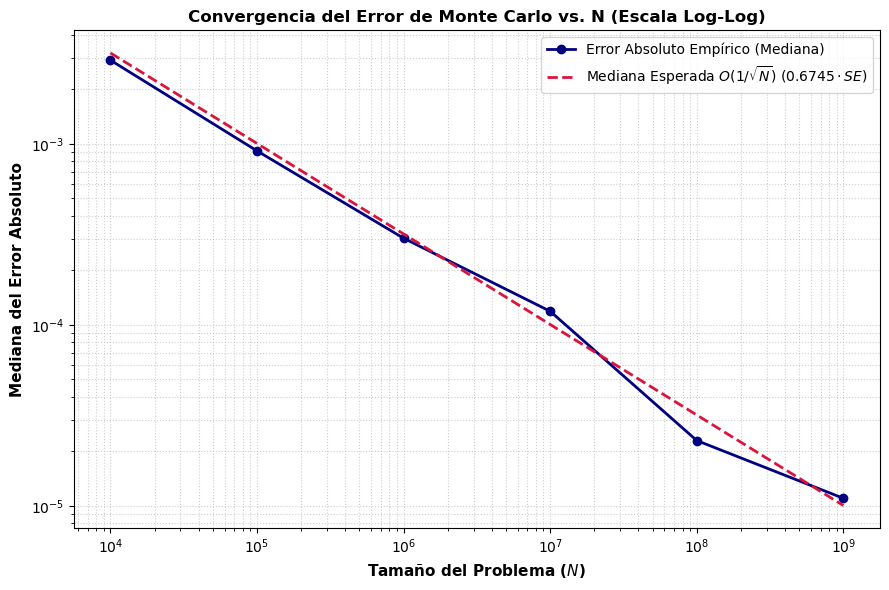

In [21]:
# ==============================================================================
# PASO A4.3: Gráfico 3 - Convergencia del Error Absoluto vs. N (Log-Log)
# ==============================================================================

plt.figure(figsize=(9, 6))

df_error_am = df_agg_am.groupby('N')['error_abs_mediana'].median().reset_index()

n_array = np.array(df_error_am['N'], dtype=float)
error_empirico = np.array(df_error_am['error_abs_mediana'], dtype=float)

# Factor de la mediana de una normal plegada: Phi^{-1}(0.75)
factor_mediana = 0.6744897501960817
p_teo = 2.0 / 3.0
se_teorico = np.sqrt((p_teo * (1.0 - p_teo)) / n_array)
error_teorico = factor_mediana * se_teorico

plt.loglog(n_array, error_empirico, marker='o', linewidth=2, color='navy', label='Error Absoluto Empírico (Mediana)')
plt.loglog(n_array, error_teorico, linestyle='--', color='crimson', linewidth=2, label=r'Mediana Esperada $O(1/\sqrt{N})$ ($0.6745 \cdot SE$)')

plt.xlabel('Tamaño del Problema ($N$)', fontsize=11, fontweight='bold')
plt.ylabel('Mediana del Error Absoluto', fontsize=11, fontweight='bold')
plt.title('Convergencia del Error de Monte Carlo vs. N (Escala Log-Log)', fontsize=12, fontweight='bold')
plt.grid(True, which='both', linestyle=':', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()

plt.savefig('grafico_amdahl_convergencia.png', dpi=300)
plt.show()


## Paso A5: Validación Estocástica del Barrido (semillas, criterio Z y sesgo)

Se aplica a este conjunto de datos la misma función `validacion_estocastica` del Paso 6. Con 3 repeticiones y 28 valores de $P$, cada $N$ tiene $n = 84$ corridas ($M = 3$), por lo que el test se hace por $N$ (6 celdas).


In [22]:
# ==============================================================================
# PASO A5: Validación estocástica del barrido P = 1..28 (clúster)
# ==============================================================================
if df_amdahl is not None:
    tabla_amdahl = validacion_estocastica(df_amdahl, 'Clúster, barrido P = 1..28 (3 repeticiones)')


==================== Clúster, barrido P = 1..28 (3 repeticiones) ====================
--- Validación de Semillas ---
Total de corridas registradas: 504 | semillas únicas: 504
✓ ÉXITO: todas las corridas tienen semillas distintas.

--- Criterio Z por corrida ---
Corridas con |z| < 2: 95.44% (esperado ≈ 95%)

--- Test de sesgo por (M, N): t = z_medio · √n ---
Celdas (M, N): 6 | con |t| > 2: 0 (esperado por azar ≈ 0.3) | con |t| > 3: 0 (esperado ≈ 0.02) | máx |t| = 1.59


n  z_medio  pct_z_negativo  pct_dentro_z2      t
M N                                                            
3 10000       84   -0.014          51.190         95.238 -0.125
  100000      84    0.033          45.238         95.238  0.307
  1000000     84   -0.049          51.190         96.429 -0.451
  10000000    84    0.084          51.190         95.238  0.768
  100000000   84    0.173          33.333         97.619  1.588
  1000000000  84   -0.082          54.762         92.857 -0.748

### Interpretación de la validación estocástica del barrido

**Conclusión: no hay evidencia de sesgo en este conjunto de datos.** Las 504 semillas son distintas, la tasa con $\vert z \vert < 2$ es 95.44 % (esperado: ≈ 95 %) y ninguno de los 6 $N$ tiene $\vert t \vert > 2$ (el máximo es $t = 1.59$ con $N = 10^8$; los demás van de $-0.75$ a $0.77$). Se esperaba por azar ≈ 0.27 celdas con $\vert t \vert > 2$. Como cada $N$ tiene $n = 84$, el test es comparable en potencia al de la Mac ($n = 80$).


## Paso A6: Resumen Sintético de Hallazgos

| Granularidad ($N$) | $P^*$ observado | Speedup máximo ($S_p^*$) | Eficiencia a $P=28$ | Karp-Flatt $e(28)$ | Régimen dominante |
| --- | --- | --- | --- | --- | --- |
| **$10^4$** | ≈ 15 (orientativo) | 8.0 | 0.20 | 0.147 | Overhead de sincronización y reducción: ≈ 43 µs con $P = 28$ frente a $T_1 = 304$ µs |
| **$10^5$** | 27 (el modelo predice ≈ 44, fuera del barrido) | 20.0 | 0.68 | 0.017 | Transición: el overhead (≈ 50 µs) es ≈ 32 % de $T_p$ |
| **$10^6$** | 28 | 26.6 | 0.95 | 0.0020 | Cómputo local; overhead ≈ 5 % de $T_p$ |
| **$10^7$** | 28 | 27.6 | 0.987 | 0.0005 | Cómputo local; overhead ≈ 1.3 % |
| **$10^8$** | 28 | 27.9 | 0.995 | 0.0002 | Cómputo local; overhead ≈ 0.5 % |
| **$10^9$** | 28 | 27.9 | 0.996 | 0.00015 | Cómputo local; overhead ≈ 0.4 % |

**Conclusiones:**

1. El overhead medido ($T_p - T_1/P$) con $N = 10^4$ y $10^5$ prácticamente coincide y crece con $P$: ≈ 6 µs + 1.54 µs·$P$ ($R^2 \approx 0.82$). La parte no paralelizable es, entonces, un **costo de sincronización y reducción casi independiente de $N$** que crece con el número de procesos, y no una fracción fija del programa.
2. Por eso la fracción secuencial efectiva depende de la granularidad: $e(28)$ baja de $0.147$ ($N = 10^4$) a $0.00015$ ($N = 10^9$). Es el comportamiento que predice Amdahl para una parte serial de tiempo aproximadamente fijo: al crecer $T_1$, su peso relativo se diluye.
3. Con el modelo $T_p \approx T_1/P + c_0 + \alpha P$, el óptimo es $P^* \approx \sqrt{T_1/\alpha}$: ≈ 14 (observado: 15) para $N = 10^4$ y ≈ 44 para $N = 10^5$ (fuera del barrido). Además predice $S(28)$ con error menor al 1 % para $N = 10^5$ y $10^6$ (este último, fuera de la muestra de ajuste) y subestima un 10 % para $N = 10^4$, el punto más ruidoso.
4. Para $N \ge 10^7$ el overhead es de 0.1 a 0.6 % de $T_p$ y no crece con $P$ (ruido o efectos de frecuencia, no de comunicación): el escalado es casi lineal hasta $P = 28$.
5. **Salvedades:** 3 repeticiones por punto; reloj de 1 µs (afecta a $N \le 10^5$); un solo recurso (192 GB / 48 cores) sin registro de `cpu.max` ni de la carga del nodo; el modelo es una hipótesis ajustada a medianas y no distingue entre sincronización, reducción y desfase de arranque de los procesos.


## Experimento: Impacto de la Barrera de Sincronización en Mac M1

Se compara la ejecución estándar de `monty_hall` (con `MPI_Barrier` previa al cómputo) frente a la versión `SIN_BARRERA`.
Se evalúa la mediana del tiempo de ejecución ($T_p$), el *Speedup* ($S_p$) y la dispersión entre repeticiones mediante el Rango Intercuartílico ($\text{IQR} = Q_3 - Q_1$).

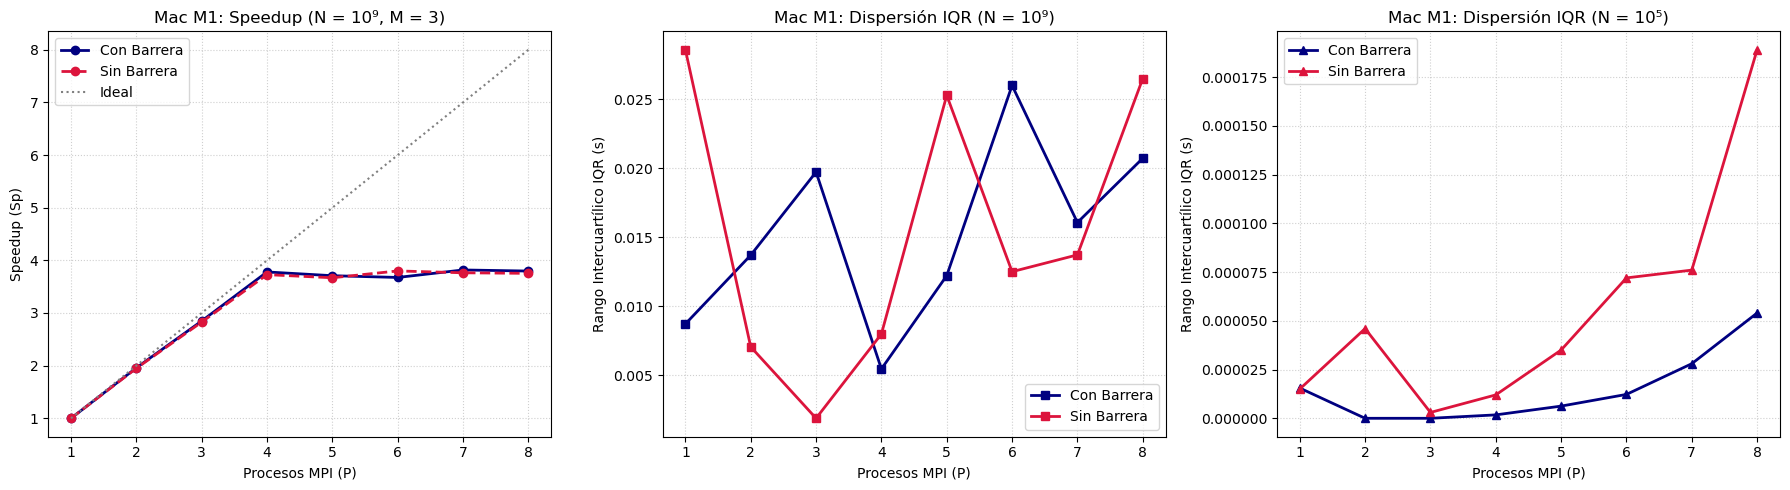

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================================================================
# Experimento Sin Barrera: Mac M1 (con vs. sin MPI_Barrier)
# ==============================================================================

path_mac_con = "datos/resultados_mac_v2.csv"
path_mac_sin = "datos/resultados_mac_sinbarrera_v2.csv"


def iqr(x):
  return np.percentile(x, 75) - np.percentile(x, 25)


# Carga defensiva
if not os.path.exists(path_mac_con) or not os.path.exists(path_mac_sin):
  print(
      "Advertencia: Verifique que ambos archivos existan en 'analisis/datos/'."
  )
else:
  df_con = pd.read_csv(
      path_mac_con, dtype={"n_procesos": "int32", "N": "int64", "M": "int32"}
  )
  df_sin = pd.read_csv(
      path_mac_sin, dtype={"n_procesos": "int32", "N": "int64", "M": "int32"}
  )

  df_con["modo"] = "Con Barrera"
  df_sin["modo"] = "Sin Barrera"
  df_mac = pd.concat([df_con, df_sin], ignore_index=True)

  # Agregación por medianas e IQR
  agg_mac = (
      df_mac.groupby(["modo", "M", "N", "n_procesos"])
      .agg(
          Tp=("tiempo", "median"),
          IQR_T=("tiempo", iqr),
          error_mediana=("error_abs", "median"),
      )
      .reset_index()
  )

  # Cálculo de T1 por modo
  df_t1 = agg_mac[agg_mac["n_procesos"] == 1][["modo", "M", "N", "Tp"]].rename(
      columns={"Tp": "T1"}
  )
  agg_mac = pd.merge(agg_mac, df_t1, on=["modo", "M", "N"], how="left")
  agg_mac["speedup"] = agg_mac["T1"] / agg_mac["Tp"]

  # Filtrado para M = 3 y N = 10^9 (Granularidad Gruesa)
  sub_g = agg_mac[(agg_mac["M"] == 3) & (agg_mac["N"] == 1000000000)]

  # Filtrado para M = 3 y N = 10^5 (Granularidad Fina)
  sub_f = agg_mac[(agg_mac["M"] == 3) & (agg_mac["N"] == 100000)]

  # Generación de Gráficos Comparativos
  fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

  # Panel 1: Speedup N = 10^9
  for modo, color, style in [
      ("Con Barrera", "navy", "-"),
      ("Sin Barrera", "crimson", "--"),
  ]:
    s = sub_g[sub_g["modo"] == modo].sort_values("n_procesos")
    ax1.plot(
        s["n_procesos"],
        s["speedup"],
        marker="o",
        color=color,
        linestyle=style,
        linewidth=2,
        label=modo,
    )
  p_vals = sorted(sub_g["n_procesos"].unique())
  ax1.plot(p_vals, p_vals, linestyle=":", color="gray", label="Ideal")
  ax1.set_xlabel("Procesos MPI (P)")
  ax1.set_ylabel("Speedup (Sp)")
  ax1.set_title("Mac M1: Speedup (N = 10⁹, M = 3)")
  ax1.set_xticks(p_vals)
  ax1.grid(True, linestyle=":", alpha=0.6)
  ax1.legend()

  # Panel 2: Dispersión IQR N = 10^9 (Granularidad Gruesa)
  for modo, color in [("Con Barrera", "navy"), ("Sin Barrera", "crimson")]:
    s = sub_g[sub_g["modo"] == modo].sort_values("n_procesos")
    ax2.plot(
        s["n_procesos"],
        s["IQR_T"],
        marker="s",
        color=color,
        linewidth=2,
        label=modo,
    )
  ax2.set_xlabel("Procesos MPI (P)")
  ax2.set_ylabel("Rango Intercuartílico IQR (s)")
  ax2.set_title("Mac M1: Dispersión IQR (N = 10⁹)")
  ax2.set_xticks(p_vals)
  ax2.grid(True, linestyle=":", alpha=0.6)
  ax2.legend()

  # Panel 3: Dispersión IQR N = 10^5 (Granularidad Fina)
  for modo, color in [("Con Barrera", "navy"), ("Sin Barrera", "crimson")]:
    s = sub_f[sub_f["modo"] == modo].sort_values("n_procesos")
    ax3.plot(
        s["n_procesos"],
        s["IQR_T"],
        marker="^",
        color=color,
        linewidth=2,
        label=modo,
    )
  ax3.set_xlabel("Procesos MPI (P)")
  ax3.set_ylabel("Rango Intercuartílico IQR (s)")
  ax3.set_title("Mac M1: Dispersión IQR (N = 10⁵)")
  ax3.set_xticks(p_vals)
  ax3.grid(True, linestyle=":", alpha=0.6)
  ax3.legend()

  plt.tight_layout()
  plt.savefig("grafico_mac_barrera_vs_sinbarrera.png", dpi=300)
  plt.show()

## Experimento: Impacto de la Barrera de Sincronización en Clúster (AMD EPYC)

En el clúster con concurrencia elevada ($P \le 28$), se analiza si la ausencia de `MPI_Barrier` genera desfasaje en la toma de tiempos del proceso raíz ($P=0$) durante el inicio del cronómetro.

In [7]:
"""
Comparación del experimento con/sin MPI_Barrier previa al cronómetro.
Genera 3 paneles: speedup, dispersión (IQR) y diferencia porcentual.
"""
import os
import matplotlib
matplotlib.use("Agg")  # seguro en headless (JupyterHub, SSH)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


PATH_CON = "datos/resultados_cluster_v2.csv"
PATH_SIN = "datos/resultados_cluster_sinbarrera_v2.csv"
OUT_FIG  = "datos/grafico_cluster_barrera_vs_sinbarrera.png"


def iqr(x):
    return np.percentile(x, 75) - np.percentile(x, 25)


def cargar(path, modo):
    if not os.path.exists(path):
        raise FileNotFoundError(f"No existe: {path}")
    df = pd.read_csv(path, dtype={"n_procesos": "int32", "N": "int64", "M": "int32"})
    df.columns = df.columns.str.strip()
    df["modo"] = modo
    return df


def verificar_semillas(df_con, df_sin):
    if "semilla" not in df_con.columns or "semilla" not in df_sin.columns:
        print("⚠️  No hay columna 'semilla'; no se verifica independencia.")
        return
    s_con, s_sin = set(df_con["semilla"]), set(df_sin["semilla"])
    comunes = s_con & s_sin
    if comunes:
        print(f"🔴 ALERTA: {len(comunes)} semillas aparecen en ambos archivos. "
              f"Los datos NO son independientes.")
        print(f"   Ejemplos: {list(comunes)[:5]}")
    else:
        print(f"✓ Semillas: {len(s_con)} con barrera, {len(s_sin)} sin barrera, 0 comunes.")


def main():
    print("=" * 60)
    print("Experimento: Con Barrera vs Sin Barrera (Clúster)")
    print("=" * 60)

    if not (os.path.exists(PATH_CON) and os.path.exists(PATH_SIN)):
        print("❌ Falta uno de los archivos de entrada.")
        return

    # 1. Carga
    df_con = cargar(PATH_CON, "Con Barrera")
    df_sin = cargar(PATH_SIN, "Sin Barrera")
    df = pd.concat([df_con, df_sin], ignore_index=True)
    print(f"✓ Filas: {len(df_con)} con barrera, {len(df_sin)} sin barrera.")

    # 2. Independencia
    verificar_semillas(df_con, df_sin)

    # 3. Agregación
    agg = (df.groupby(["modo", "M", "N", "n_procesos"])
             .agg(Tp=("tiempo", "median"),
                  IQR_T=("tiempo", iqr),
                  n_reps=("tiempo", "size"),
                  error_med=("error_abs", "median"))
             .reset_index())
    t1 = (agg[agg["n_procesos"] == 1][["modo", "M", "N", "Tp"]]
            .rename(columns={"Tp": "T1"}))
    agg = agg.merge(t1, on=["modo", "M", "N"], how="left")
    agg["speedup"] = agg["T1"] / agg["Tp"]

    # 4. Intersección de N y M
    n_comun = sorted(set(df_con["N"]) & set(df_sin["N"]))
    m_comun = sorted(set(df_con["M"]) & set(df_sin["M"]))
    print(f"✓ N comunes entre modos: {n_comun}")
    print(f"✓ M comunes entre modos: {m_comun}")
    if not n_comun or not m_comun:
        print("❌ Sin intersección de N o M; abortando.")
        return

    n_fina, n_gruesa = min(n_comun), max(n_comun)
    m_eval = 3 if 3 in m_comun else m_comun[0]

    # 5. Subconjuntos
    sub_cg = agg[(agg["M"] == m_eval) & (agg["N"] == n_gruesa)].copy()
    sub_cf = agg[(agg["M"] == m_eval) & (agg["N"] == n_fina)].copy()

    # P comunes en ambos modos para cada granularidad
    p_cg = set(sub_cg[sub_cg["modo"] == "Con Barrera"]["n_procesos"]) & \
           set(sub_cg[sub_cg["modo"] == "Sin Barrera"]["n_procesos"])
    p_cf = set(sub_cf[sub_cf["modo"] == "Con Barrera"]["n_procesos"]) & \
           set(sub_cf[sub_cf["modo"] == "Sin Barrera"]["n_procesos"])
    p_cg, p_cf = sorted(p_cg), sorted(p_cf)
    print(f"✓ P comunes (N={n_gruesa}): {p_cg}")
    print(f"✓ P comunes (N={n_fina}):   {p_cf}")

    # 6. Figura: 3 paneles
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    colores   = {"Con Barrera": "navy",     "Sin Barrera": "darkgreen"}
    estilos   = {"Con Barrera": "-",        "Sin Barrera": "--"}
    marcadores = {"Con Barrera": "o",       "Sin Barrera": "s"}

    # Panel 1: Speedup (N grande, P comunes)
    ax = axes[0]
    for modo in ["Con Barrera", "Sin Barrera"]:
        s = sub_cg[(sub_cg["modo"] == modo) & (sub_cg["n_procesos"].isin(p_cg))]
        s = s.sort_values("n_procesos")
        if not s.empty:
            ax.plot(s["n_procesos"], s["speedup"],
                    marker=marcadores[modo], linestyle=estilos[modo],
                    color=colores[modo], linewidth=2, label=modo)
    if p_cg:
        ax.plot(p_cg, p_cg, ":", color="gray", label="Ideal")
        ax.set_xticks(p_cg)
    ax.set_xlabel("Procesos MPI (P)")
    ax.set_ylabel("Speedup $S_p$")
    ax.set_title(f"Speedup: con vs sin barrera\n(M={m_eval}, N={n_gruesa:.0e})")
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend()

    # Panel 2: IQR (N chico, P comunes)
    ax = axes[1]
    for modo in ["Con Barrera", "Sin Barrera"]:
        s = sub_cf[(sub_cf["modo"] == modo) & (sub_cf["n_procesos"].isin(p_cf))]
        s = s.sort_values("n_procesos")
        if not s.empty:
            ax.plot(s["n_procesos"], s["IQR_T"] * 1000,
                    marker=marcadores[modo], linestyle=estilos[modo],
                    color=colores[modo], linewidth=2, label=modo)
    if p_cf:
        ax.set_xticks(p_cf)
    ax.set_xlabel("Procesos MPI (P)")
    ax.set_ylabel("IQR del tiempo (ms)")
    ax.set_title(f"Dispersión (IQR): con vs sin barrera\n(M={m_eval}, N={n_fina:.0e})")
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend()

    # Panel 3: Diferencia porcentual del speedup
    ax = axes[2]
    piv = (agg.pivot_table(index=["M", "N", "n_procesos"],
                            columns="modo", values="speedup")
              .reset_index()
              .dropna(subset=["Con Barrera", "Sin Barrera"]))
    piv["diff_%"] = 100 * (piv["Sin Barrera"] - piv["Con Barrera"]) / piv["Con Barrera"]
    piv_m = piv[piv["M"] == m_eval]
    n_vals = sorted(piv_m["N"].unique())
    colormap = plt.cm.viridis(np.linspace(0.15, 0.9, max(len(n_vals), 1)))
    for n_val, color in zip(n_vals, colormap):
        s = piv_m[piv_m["N"] == n_val].sort_values("n_procesos")
        if not s.empty:
            ax.plot(s["n_procesos"], s["diff_%"],
                    marker="o", color=color, linewidth=1.8, label=f"N={n_val:.0e}")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Procesos MPI (P)")
    ax.set_ylabel("Δ Speedup (sin−con)/con [%]")
    ax.set_title("Impacto de quitar la barrera\nsobre el speedup mediano")
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(title=f"M={m_eval}", fontsize=8)

    plt.tight_layout()
    os.makedirs(os.path.dirname(OUT_FIG), exist_ok=True)
    plt.savefig(OUT_FIG, dpi=300, bbox_inches="tight")
    print(f"\n✓ Figura guardada en: {OUT_FIG}")
    # plt.show() solo si estás en entorno interactivo
    try:
        plt.show()
    except Exception:
        pass

    # 7. Tabla resumen (sin display)
    n_antes = len(piv) + (len(agg.pivot_table(index=["M", "N", "n_procesos"],
                                              columns="modo", values="speedup")
                              .reset_index()) - len(piv))
    print(f"\n--- Resumen comparativo de speedup (M={m_eval}) ---")
    cols = ["M", "N", "n_procesos", "Con Barrera", "Sin Barrera", "diff_%"]
    with pd.option_context("display.max_rows", 40,
                            "display.float_format", "{:.4f}".format):
        print(piv[piv["M"] == m_eval][cols].to_string(index=False))

    # Estadístico global
    print("\n--- Resumen global ---")
    print(f"Δ% medio  : {piv['diff_%'].mean():+.3f}%")
    print(f"Δ% mediano: {piv['diff_%'].median():+.3f}%")
    print(f"Δ% |max|  : {piv['diff_%'].abs().max():.3f}%")
    print(f"Signo: {(piv['diff_%'] > 0).sum()} positivos, "
          f"{(piv['diff_%'] < 0).sum()} negativos, "
          f"{(piv['diff_%'] == 0).sum()} ceros")


if __name__ == "__main__":
    main()

Experimento: Con Barrera vs Sin Barrera (Clúster)
✓ Filas: 800 con barrera, 420 sin barrera.
✓ Semillas: 800 con barrera, 420 sin barrera, 0 comunes.
✓ N comunes entre modos: [100000, 1000000]
✓ M comunes entre modos: [3]
✓ P comunes (N=1000000): [1, 2, 3, 4, 5, 6, 7, 8]
✓ P comunes (N=100000):   [1, 2, 3, 4, 5, 6, 7, 8]

✓ Figura guardada en: datos/grafico_cluster_barrera_vs_sinbarrera.png

--- Resumen comparativo de speedup (M=3) ---
 M       N  n_procesos  Con Barrera  Sin Barrera   diff_%
 3  100000           1       1.0000       1.0000   0.0000
 3  100000           2       1.9875       1.9702  -0.8716
 3  100000           3       2.9735       2.7648  -7.0210
 3  100000           4       3.8985       3.6675  -5.9251
 3  100000           5       4.8450       4.6332  -4.3729
 3  100000           6       5.8327       5.4260  -6.9722
 3  100000           7       6.5649       5.7652 -12.1827
 3  100000           8       7.6980       5.7652 -25.1082
 3 1000000           1       1.0000   

/var/folders/kk/mgm2wshd6f3dngr18t8k8gjc0000gn/T/ipykernel_81904/1122396957.py:169: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  plt.show()


=== PROCESANDO DATOS Y VERIFICANDO INTEGRIDAD ===
[mac_serial] Repeticiones por (N, P): mín = 10, máx = 10
[mac_sin_barrera] Repeticiones por (N, P): mín = 5, máx = 5
[mac_con_barrera] Repeticiones por (N, P): mín = 10, máx = 10
[cluster_serial] Repeticiones por (N, P): mín = 10, máx = 10
[cluster_sin_barrera] Repeticiones por (N, P): mín = 5, máx = 5
  -> AVISO: Valores de speedup exactamente iguales detectados en cluster_sin_barrera:
     N  n_procesos  Speedup
 10000          12 2.460317
 10000          15 1.791908
 10000          18 2.460317
 10000          20 1.791908
100000           7 5.765152
100000           8 5.765152
[cluster_con_barrera] Repeticiones por (N, P): mín = 5, máx = 5

=== GENERANDO TABLA 1: SERIAL VS MPI (P=1) ===
Exportado: tabla_serial.csv
Sistema          N  T_Serial  T_MPI_P1  Diferencia_%
    Mac     100000  0.000179  0.000189      5.865922
    Mac    1000000  0.001924  0.001895     -1.532866
    Mac   10000000  0.018112  0.018538      2.354792
    Mac  100

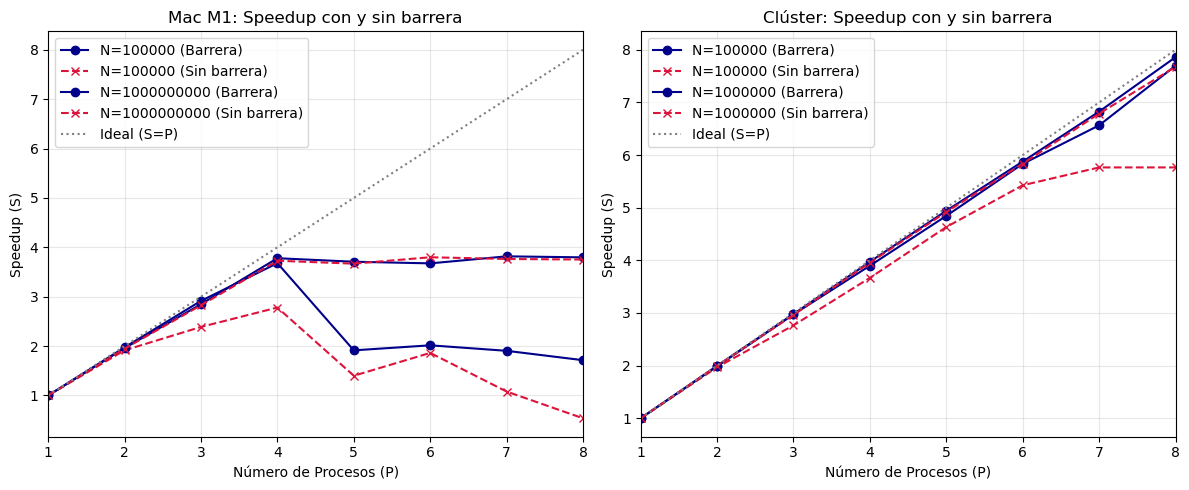

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# =============================================================================
# 0. CONFIGURACIÓN DE RUTAS (Reemplaza con tus rutas reales)
# =============================================================================
rutas = {
    'mac_serial': 'datos/resultados_mac_serial.csv',
    'mac_sin_barrera': 'datos/resultados_mac_sinbarrera_v2.csv',
    'mac_con_barrera': 'datos/resultados_mac_v2.csv',
    'cluster_serial': 'datos/resultados_linux_serial.csv',
    'cluster_sin_barrera': 'datos/resultados_cluster_sinbarrera_v2.csv',
    'cluster_con_barrera': 'datos/resultados_cluster_v2.csv'
}

# =============================================================================
# 1. FUNCIONES DE CARGA Y PROCESAMIENTO
# =============================================================================
def cargar_y_procesar(ruta, nombre_serie):
    """
    Carga el CSV, filtra M=3, calcula la mediana del tiempo por (N, P),
    deriva T1, calcula el Speedup y emite los avisos por consola.
    """
    if not os.path.exists(ruta):
        print(f"--- Faltante: No se encontró el archivo {ruta} ---")
        return pd.DataFrame()

    df = pd.read_csv(ruta)
    
    # Adaptación para archivos seriales que puedan no tener 'n_procesos' o 'M'
    if 'n_procesos' not in df.columns:
        df['n_procesos'] = 1
    else:
        # CORRECCIÓN: Si el serial exportó P=0, lo estandarizamos a P=1 para calcular Speedup
        df.loc[df['n_procesos'] == 0, 'n_procesos'] = 1
        
    if 'M' not in df.columns:
        df['M'] = 3
        
    # Filtrar solo M=3
    df = df[df['M'] == 3].copy()
    if df.empty:
        return pd.DataFrame()

    # Aviso: Cantidad de repeticiones por punto
    reps = df.groupby(['N', 'n_procesos']).size()
    print(f"[{nombre_serie}] Repeticiones por (N, P): mín = {reps.min()}, máx = {reps.max()}")

    # Calcular mediana
    df_agg = df.groupby(['N', 'n_procesos'])['tiempo'].median().reset_index()
    df_agg.rename(columns={'tiempo': 'T_mediana'}, inplace=True)

    # Extraer T1 (tiempo con P=1) para la misma serie
    df_t1 = df_agg[df_agg['n_procesos'] == 1][['N', 'T_mediana']].rename(columns={'T_mediana': 'T1'})
    
    # Aviso: Faltantes de P=1
    ns_totales = set(df_agg['N'].unique())
    ns_con_t1 = set(df_t1['N'].unique())
    faltantes_t1 = ns_totales - ns_con_t1
    if faltantes_t1:
        print(f"  -> AVISO: Falta P=1 en {nombre_serie} para N={faltantes_t1}. No se podrá calcular Speedup ahí.")

    # Unir T1 y calcular Speedup
    df_agg = pd.merge(df_agg, df_t1, on='N', how='inner')
    df_agg['Speedup'] = df_agg['T1'] / df_agg['T_mediana']

    # Aviso: Valores de speedup repetidos exactamente (sospechoso)
    duplicados = df_agg[df_agg.duplicated(subset=['N', 'Speedup'], keep=False)]
    if not duplicados.empty:
        print(f"  -> AVISO: Valores de speedup exactamente iguales detectados en {nombre_serie}:")
        print(duplicados[['N', 'n_procesos', 'Speedup']].to_string(index=False))

    return df_agg

# Cargar todos los datasets
datos = {}
print("=== PROCESANDO DATOS Y VERIFICANDO INTEGRIDAD ===")
for clave, ruta in rutas.items():
    datos[clave] = cargar_y_procesar(ruta, clave)

# =============================================================================
# 2. TABLA 1: SERIAL VS MPI (P=1)
# =============================================================================
print("\n=== GENERANDO TABLA 1: SERIAL VS MPI (P=1) ===")
filas_tabla1 = []

for sistema, cl_serial, cl_barrera in [('Mac', 'mac_serial', 'mac_con_barrera'), 
                                       ('Cluster', 'cluster_serial', 'cluster_con_barrera')]:
    if not datos[cl_serial].empty and not datos[cl_barrera].empty:
        df_s = datos[cl_serial][datos[cl_serial]['n_procesos'] == 1][['N', 'T_mediana']]
        df_m = datos[cl_barrera][datos[cl_barrera]['n_procesos'] == 1][['N', 'T_mediana']]
        
        merged = pd.merge(df_s, df_m, on='N', suffixes=('_serial', '_mpi'))
        merged['Sistema'] = sistema
        merged['Dif_%'] = ((merged['T_mediana_mpi'] - merged['T_mediana_serial']) / merged['T_mediana_serial']) * 100
        filas_tabla1.append(merged)

if filas_tabla1:
    tabla_serial = pd.concat(filas_tabla1, ignore_index=True)
    tabla_serial = tabla_serial[['Sistema', 'N', 'T_mediana_serial', 'T_mediana_mpi', 'Dif_%']]
    tabla_serial.columns = ['Sistema', 'N', 'T_Serial', 'T_MPI_P1', 'Diferencia_%']
    
    tabla_serial.to_csv('tabla_serial.csv', index=False)
    print("Exportado: tabla_serial.csv")
    print(tabla_serial.to_string(index=False))

# =============================================================================
# 3. FIGURA: SPEEDUP CON Y SIN BARRERA
# =============================================================================
print("\n=== GENERANDO GRÁFICA DE SPEEDUP ===")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
configs_grafico = [
    ('Mac M1', 'mac_con_barrera', 'mac_sin_barrera', [10**5, 10**9], axes[0]),
    ('Clúster', 'cluster_con_barrera', 'cluster_sin_barrera', [10**5, 10**6], axes[1])
]

for titulo, cl_con, cl_sin, ns_graficar, ax in configs_grafico:
    df_con = datos.get(cl_con, pd.DataFrame())
    df_sin = datos.get(cl_sin, pd.DataFrame())
    
    for n_val in ns_graficar:
        # Plot Con Barrera
        if not df_con.empty and n_val in df_con['N'].values:
            sub_con = df_con[(df_con['N'] == n_val) & (df_con['n_procesos'] <= 8)].sort_values('n_procesos')
            ax.plot(sub_con['n_procesos'], sub_con['Speedup'], 
                    color='darkblue', linestyle='-', marker='o', 
                    label=f'N={n_val} (Barrera)')
            
        # Plot Sin Barrera
        if not df_sin.empty and n_val in df_sin['N'].values:
            sub_sin = df_sin[(df_sin['N'] == n_val) & (df_sin['n_procesos'] <= 8)].sort_values('n_procesos')
            ax.plot(sub_sin['n_procesos'], sub_sin['Speedup'], 
                    color='crimson', linestyle='--', marker='x', 
                    label=f'N={n_val} (Sin barrera)')

    # Línea Ideal S = P
    ax.plot([1, 8], [1, 8], color='gray', linestyle=':', label='Ideal (S=P)')
    
    ax.set_title(f"{titulo}: Speedup con y sin barrera")
    ax.set_xlabel("Número de Procesos (P)")
    ax.set_ylabel("Speedup (S)")
    ax.set_xlim(1, 8)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig('grafico_barrera.png', dpi=300, bbox_inches='tight')
print("Exportado: grafico_barrera.png")

# =============================================================================
# 4. TABLA 3: COMPARATIVA DE SPEEDUPS (SISTEMA, N, P)
# =============================================================================
print("\n=== GENERANDO TABLA 3: SPEEDUPS BARRERA VS SIN BARRERA ===")
filas_tabla3 = []

for sistema, cl_con, cl_sin in [('Mac', 'mac_con_barrera', 'mac_sin_barrera'), 
                                ('Cluster', 'cluster_con_barrera', 'cluster_sin_barrera')]:
    if not datos[cl_con].empty and not datos[cl_sin].empty:
        merged = pd.merge(datos[cl_con][['N', 'n_procesos', 'Speedup']], 
                          datos[cl_sin][['N', 'n_procesos', 'Speedup']], 
                          on=['N', 'n_procesos'], suffixes=('_con', '_sin'))
        
        merged['Sistema'] = sistema
        merged['Dif_%'] = ((merged['Speedup_sin'] - merged['Speedup_con']) / merged['Speedup_con']) * 100
        filas_tabla3.append(merged)

if filas_tabla3:
    tabla_barrera = pd.concat(filas_tabla3, ignore_index=True)
    tabla_barrera = tabla_barrera[['Sistema', 'N', 'n_procesos', 'Speedup_con', 'Speedup_sin', 'Dif_%']]
    tabla_barrera.columns = ['Sistema', 'N', 'P', 'S_Barrera', 'S_Sin_Barrera', 'Diferencia_%']
    
    tabla_barrera.to_csv('tabla_barrera.csv', index=False)
    print("Exportado: tabla_barrera.csv")
    print(tabla_barrera.to_string(index=False))

In [24]:
import pandas as pd, numpy as np

d = pd.read_csv("datos/resultados_windows_v2.csv")

# --- Controles de integridad ---
print("filas:", len(d), "| semillas únicas:", d.semilla.nunique())
reps = d.groupby(["M", "N", "n_procesos"]).size()
print("repeticiones por punto: mín", reps.min(), "máx", reps.max(), "| puntos:", len(reps))
print("nulos:", int(d.isna().sum().sum()), "| tiempos <= 0:", int((d.tiempo <= 0).sum()))
g = d[d.N == 10**9]
print("\nDiferencia media con la teoría (N = 10^9), por M:")
print((g.p_empirico - g.p_teorico).groupby(g.M).mean())

# --- Medianas, speedup y eficiencia ---
a = d.groupby(["M", "N", "n_procesos"]).tiempo.agg(
    Tp="median",
    IQR=lambda x: x.quantile(.75) - x.quantile(.25)).reset_index()
t1 = a[a.n_procesos == 1].set_index(["M", "N"]).Tp.rename("T1")
a = a.join(t1, on=["M", "N"])
a["speedup"] = a.T1 / a.Tp
a["efic"] = a.speedup / a.n_procesos
a["disp_rel"] = a.IQR / a.Tp                      # dispersión relativa
a["ns_iter"] = a.Tp * a.n_procesos / a.N * 1e9    # costo por iteración y por proceso
m3 = a[a.M == 3]

print("\n--- Tabla 7: speedup y eficiencia (M = 3) ---")
print(m3[m3.n_procesos.isin([4, 8])]
      .pivot(index="N", columns="n_procesos", values=["speedup", "efic"]).round(2))

print("\n--- Diagnóstico: eficiencia con P = 2, T1 y dispersión por N ---")
print(m3[m3.n_procesos == 2][["N", "efic"]].round(3).to_string(index=False))
print(m3[m3.n_procesos == 1][["N", "T1", "disp_rel"]].round(4).to_string(index=False))

print("\n--- ns por iteración (por proceso): debería ser constante entre P ---")
print(m3.pivot(index="N", columns="n_procesos", values="ns_iter").round(1))

filas: 800 | semillas únicas: 800
repeticiones por punto: mín 5 máx 5 | puntos: 160
nulos: 0 | tiempos <= 0: 0

Diferencia media con la teoría (N = 10^9), por M:
M
3    -3.349750e-07
5    -1.411750e-07
10    2.357075e-06
50   -8.688500e-07
dtype: float64

--- Tabla 7: speedup y eficiencia (M = 3) ---
           speedup        efic      
n_procesos       4     8     4     8
N                                   
100000        2.71  2.50  0.68  0.31
1000000       3.09  4.38  0.77  0.55
10000000      3.36  4.79  0.84  0.60
100000000     3.28  5.31  0.82  0.66
1000000000    2.92  5.49  0.73  0.69

--- Diagnóstico: eficiencia con P = 2, T1 y dispersión por N ---
         N  efic
    100000 0.991
   1000000 0.959
  10000000 0.965
 100000000 0.922
1000000000 0.849
         N      T1  disp_rel
    100000  0.0040    0.0085
   1000000  0.0398    0.0049
  10000000  0.3969    0.0151
 100000000  3.9534    0.0032
1000000000 40.3559    0.0134

--- ns por iteración (por proceso): debería ser constante e

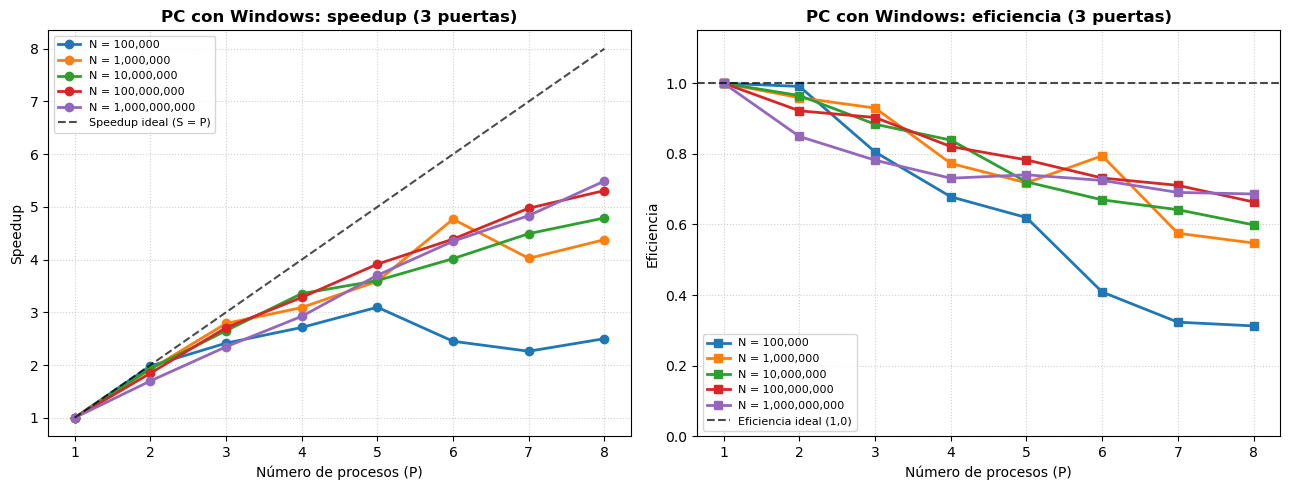

In [25]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
P = sorted(m3.n_procesos.unique())

for n in sorted(m3.N.unique()):
    s = m3[m3.N == n].sort_values("n_procesos")
    ax1.plot(s.n_procesos, s.speedup, marker="o", linewidth=2, label=f"N = {n:,}")
    ax2.plot(s.n_procesos, s.efic, marker="s", linewidth=2, label=f"N = {n:,}")

ax1.plot(P, P, "--", color="black", alpha=.7, label="Speedup ideal (S = P)")
ax2.axhline(1.0, linestyle="--", color="black", alpha=.7, label="Eficiencia ideal (1,0)")

ax1.set_title("PC con Windows: speedup (3 puertas)", fontweight="bold")
ax2.set_title("PC con Windows: eficiencia (3 puertas)", fontweight="bold")
ax1.set_ylabel("Speedup"); ax2.set_ylabel("Eficiencia")
ax2.set_ylim(0, 1.15)
for ax in (ax1, ax2):
    ax.set_xlabel("Número de procesos (P)")
    ax.set_xticks(P)
    ax.grid(True, linestyle=":", alpha=.6)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("grafico_windows_speedup_eficiencia.png", dpi=300)

In [26]:
x = m3.pivot(index="N", columns="n_procesos", values="speedup")
print(x[[4, 6, 7, 8]].round(2))
print((x[8] / x[6]).round(2).rename("S8 / S6"))

n_procesos     4     6     7     8
N                                 
100000      2.71  2.45  2.26  2.50
1000000     3.09  4.77  4.02  4.38
10000000    3.36  4.02  4.49  4.79
100000000   3.28  4.39  4.98  5.31
1000000000  2.92  4.35  4.84  5.49
N
100000        1.02
1000000       0.92
10000000      1.19
100000000     1.21
1000000000    1.26
Name: S8 / S6, dtype: float64
